# Microbioma bacteriano × plásticos no solo — alfa, beta e PCoA por variável

**Dados:** 553 amostras de 16S do `conjunto_alex` (9 BioProjects) + metadados da aba **Metadata - Bacteria**
(planilha corrigida e padronizada). **Variáveis analisadas:**

| Tipo | Variáveis |
|---|---|
| Categóricas | `POLYMER_TYPE`, `POLYMER_SIZE`, `BIODEGRADABLE`, `SOIL_FRACTION` |
| Numéricas | `DENSITY_(g/cm³)`, `SOC(g/kg)`, `TN(g/kg)`, `C/N`, `pH`, `DOC(mg/kg)`, `NH4(mg/kg)`, `NO3(mg/kg)`, `AP(mg/kg)`, `AK(mg/kg)` |

**Análises por variável:** diversidade **alfa** (riqueza, Shannon, Faith PD) · diversidade **beta** (Bray–Curtis, PERMANOVA, PERMDISP) ·
**PCoA** · gráficos de **barra**, **dispersão** e **média**.

**Validação e busca de padrão:** (1) quanto cada variável está **confundida com o projeto**; (2) todo teste é feito duas vezes —
**global** e **dentro do projeto** (permutações restritas ao BioProject / modelo misto com projeto aleatório); (3) colinearidade entre
variáveis de solo; (4) **envfit** das variáveis numéricas na PCoA; (5) **Random Forest** com validação cruzada que deixa projetos
inteiros de fora; (6) robustez da diversidade alfa a 10 rarefações.

> **Como ler:** um efeito só é confiável se aparecer **dentro do projeto**. Efeito global que some quando o projeto é controlado
> é diferença entre estudos (solo, região do 16S, laboratório), não da variável.

In [1]:
import warnings; warnings.filterwarnings('ignore')
from pathlib import Path
import re
import numpy as np, pandas as pd
import matplotlib.pyplot as plt, seaborn as sns
from scipy import stats
import statsmodels.formula.api as smf
import skbio
from skbio.diversity import alpha_diversity, beta_diversity
from skbio.stats.ordination import pcoa
from util_analise import permanova, dispersao, clr

pd.set_option('display.width', 220); pd.set_option('display.max_columns', 40); pd.set_option('display.max_rows', 80)
sns.set_theme(style='whitegrid', context='notebook'); plt.rcParams['figure.dpi'] = 100; plt.rcParams['savefig.bbox'] = 'tight'
DATA = Path('../results/conjunto_alex'); PLAN = Path('../results/dados_complementares/Database_Plastic-Soil.xlsx')
FIG, TAB = Path('figuras/principal'), Path('tabelas/principal'); FIG.mkdir(parents=True, exist_ok=True); TAB.mkdir(parents=True, exist_ok=True)
def savefig(nome): plt.savefig(FIG / f'{nome}.png', dpi=140); plt.show()
PERMS = 999

## 1. Dados

In [2]:
asv = pd.read_csv(DATA / 'asv_table.tsv', sep='\t', index_col=0).astype(int)
tax = pd.read_csv(DATA / 'taxonomy.tsv', sep='\t', index_col=0).reindex(asv.index)
tree = skbio.TreeNode.read(str(DATA / 'tree.nwk'))
plan = pd.read_excel(PLAN, sheet_name='Metadata - Bacteria', dtype=str, keep_default_na=False).set_index('SAMPLE')
print('Planilha:', plan.shape, '| ASV:', asv.shape)
print('Amostras da planilha fora do conjunto:', plan.index.difference(asv.columns).tolist())
print('Amostras do conjunto sem metadado:', asv.columns.difference(plan.index).tolist())
meta = plan.loc[asv.columns].copy()

CAT = ['POLYMER_TYPE', 'POLYMER_SIZE', 'BIODEGRADABLE', 'SOIL_FRACTION']
NUM = ['DENSITY_(g/cm³)', 'SOC(g/kg)', 'TN(g/kg)', 'C/N', 'pH', 'DOC(mg/kg)', 'NH4(mg/kg)', 'NO3(mg/kg)', 'AP(mg/kg)', 'AK(mg/kg)']

def para_num(v):
    '''"1.18-1.26" → ponto médio 1.22; "<0.2" → metade do limite (0.1); "NA" → NaN.'''
    v = str(v).strip()
    if v in ('', 'NA'): return np.nan
    if v.startswith('<'): return float(v[1:]) / 2
    m = re.fullmatch(r'(-?\d+(?:\.\d+)?)-(-?\d+(?:\.\d+)?)', v)
    return (float(m.group(1)) + float(m.group(2))) / 2 if m else float(v)

for c in NUM: meta[c] = meta[c].map(para_num)
ROTULO_NA = {'POLYMER_TYPE': 'NA (papel)', 'POLYMER_SIZE': 'NA (sem plástico)', 'BIODEGRADABLE': 'NA (sem plástico)'}
for c in CAT: meta[c] = meta[c].replace('NA', ROTULO_NA.get(c, 'NA'))
meta['POLYMER_TYPE'] = meta.POLYMER_TYPE.replace({'NONE': 'Controle (NONE)'})

SOLO = ['Bulk', 'Rhizosphere', 'Plastisphere']
meta['CONJUNTO'] = np.where(meta.SOIL_FRACTION.isin(SOLO), 'solo', 'outro')
print('\nFrações:', meta.SOIL_FRACTION.value_counts().to_dict())
print('Inconsistência a revisar na planilha: TPS/polyester com BIODEGRADABLE = NA →',
      meta[(meta.POLYMER_TYPE == 'TPS/polyester') & meta.BIODEGRADABLE.str.startswith('NA')].index.tolist())

Planilha: (557, 48) | ASV: (47472, 553)
Amostras da planilha fora do conjunto: ['SRR11749118', 'SRR11749120', 'SRR19868794', 'SRR19868795']
Amostras do conjunto sem metadado: []

Frações: {'Bulk': 373, 'Plastisphere': 67, 'Enrichment_culture': 46, 'Rhizosphere': 43, 'Gut': 24}
Inconsistência a revisar na planilha: TPS/polyester com BIODEGRADABLE = NA → ['SRR10076379', 'SRR10076381']


**Conjuntos de amostras.** `SOIL_FRACTION` é analisada com as **553 amostras** (inclui intestino de *E. crypticus* e culturas de
enriquecimento). As demais variáveis usam as **483 amostras de solo** (bulk, rizosfera e plastisfera), para não misturar
intestino e meio de cultura com solo. `<0.2` (TN de Barba Peider) = 0,1 (metade do limite); faixas = ponto médio.

In [3]:
resumo = pd.DataFrame({
    'n_com_valor': [(meta[c].notna() & ~meta[c].astype(str).str.startswith('NA')).sum() for c in CAT + NUM],
    'n_categorias_ou_valores': [meta[c].nunique() for c in CAT + NUM],
    'projetos_com_valor': [meta.loc[meta[c].notna() & ~meta[c].astype(str).str.startswith('NA'), 'BIOPROJECT'].nunique() for c in CAT + NUM],
}, index=CAT + NUM)
resumo

,n_com_valor,n_categorias_ou_valores,projetos_com_valor
POLYMER_TYPE,529,14,9
POLYMER_SIZE,437,13,9
BIODEGRADABLE,435,3,9
SOIL_FRACTION,553,5,9
DENSITY_(g/cm³),393,8,9
SOC(g/kg),378,18,8
TN(g/kg),317,11,6
C/N,300,10,6
pH,459,17,8
DOC(mg/kg),140,7,3


## 2. Rarefação, diversidade alfa e distâncias

In [4]:
DEPTH = int(np.floor(asv.sum().min() / 1000) * 1000)
def rarefy(seed):
    rng = np.random.default_rng(seed)
    return pd.DataFrame(np.column_stack([rng.multivariate_hypergeometric(asv[s].values, DEPTH) for s in asv.columns]),
                        index=asv.index, columns=asv.columns)

def alfa(R):
    R = R.loc[R.sum(1) > 0]; ids = list(R.columns); M = R.T.values
    return pd.DataFrame({'Riqueza': alpha_diversity('observed_features', M, ids),
                         'Shannon': alpha_diversity('shannon', M, ids),
                         'FaithPD': alpha_diversity('faith_pd', M, ids, taxa=list(R.index), tree=tree, validate=False)})

# validação: 10 rarefações independentes → usamos a média; o coeficiente de variação mostra a estabilidade
reps = [alfa(rarefy(s)) for s in range(10)]
A = sum(reps) / len(reps)
cv = (pd.concat(reps, keys=range(10)).groupby(level=1).std() / A * 100)
print(f'Profundidade de rarefação: {DEPTH} leituras')
print('Coeficiente de variação entre 10 rarefações (%, mediana / máx.):')
print(cv.agg(['median', 'max']).round(2))
rare = rarefy(42)
A = A.join(meta)

Profundidade de rarefação: 12000 leituras
Coeficiente de variação entre 10 rarefações (%, mediana / máx.):
        Riqueza  Shannon  FaithPD
median     0.64     0.19     0.99
max       11.98     5.91    15.28


PCoA (553 amostras): PC1 25.8%, PC2 13.3% | PCoA solo (483): PC1 29.1%, PC2 14.6%


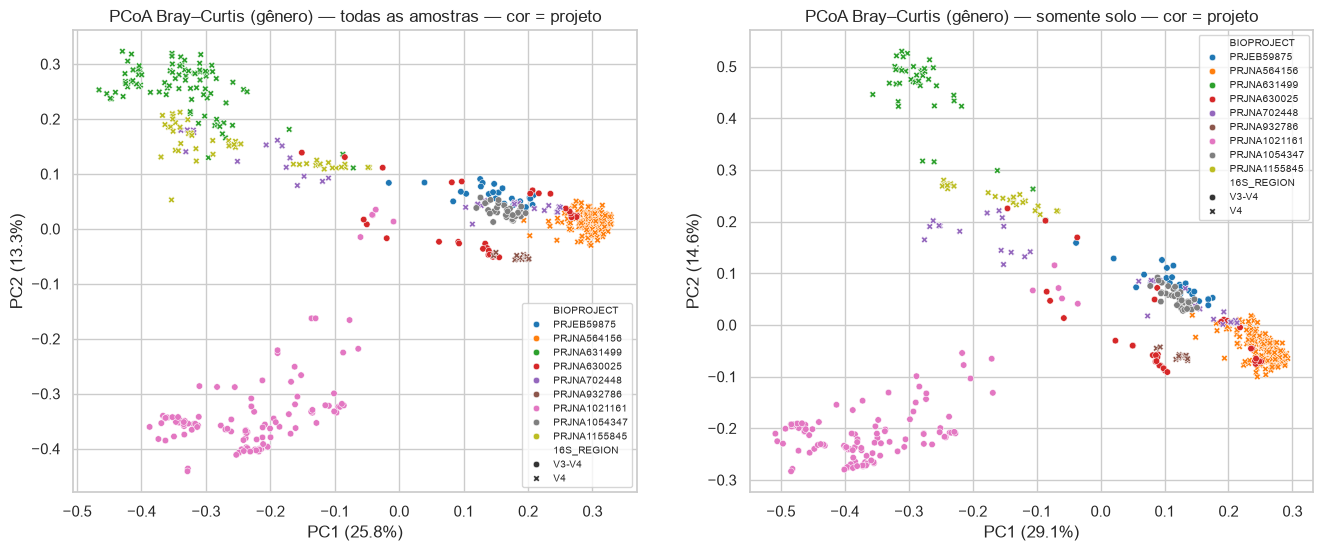

In [5]:
# Bray–Curtis: nível de gênero para comparar entre projetos (regiões V4 e V3-V4 diferentes); ASV dentro de cada projeto
lab = tax.Genus.fillna(tax.Family.fillna(tax.Order.fillna(tax.Phylum)) + ' (NC)').fillna('Não classificado')
gen = (rare / rare.sum()).groupby(lab).sum()
gen = gen.loc[(gen > 0).sum(1) >= 5]
BC = beta_diversity('braycurtis', gen.T.values, ids=list(gen.columns))
def sub_dm(ids): return BC.filter(list(ids))

ord_all = pcoa(BC, number_of_dimensions=10)
PC = ord_all.samples.iloc[:, :3].set_axis(['PC1', 'PC2', 'PC3'], axis=1); PC.index = list(gen.columns)
VE = ord_all.proportion_explained.values[:3] * 100
solo_ids = meta.index[meta.CONJUNTO == 'solo']
ord_solo = pcoa(sub_dm(solo_ids), number_of_dimensions=10)
PCs = ord_solo.samples.iloc[:, :3].set_axis(['PC1', 'PC2', 'PC3'], axis=1); PCs.index = list(solo_ids)
VEs = ord_solo.proportion_explained.values[:3] * 100
print(f'PCoA (553 amostras): PC1 {VE[0]:.1f}%, PC2 {VE[1]:.1f}% | PCoA solo (483): PC1 {VEs[0]:.1f}%, PC2 {VEs[1]:.1f}%')

fig, ax = plt.subplots(1, 2, figsize=(16, 6))
for a, (P, ve, t) in zip(ax, [(PC, VE, 'todas as amostras'), (PCs, VEs, 'somente solo')]):
    sns.scatterplot(data=P.join(meta), x='PC1', y='PC2', hue='BIOPROJECT', style='16S_REGION', s=22, ax=a, palette='tab10')
    a.set_xlabel(f'PC1 ({ve[0]:.1f}%)'); a.set_ylabel(f'PC2 ({ve[1]:.1f}%)'); a.set_title(f'PCoA Bray–Curtis (gênero) — {t} — cor = projeto'); a.legend(fontsize=7)
savefig('00_pcoa_projeto')

## 3. Diagnóstico de confusão com o projeto (validação)

Antes de interpretar qualquer variável: quanto dela é explicado pelo **BioProject**?
* Categóricas: **V de Cramér** (0 = independente, 1 = a variável é o projeto).
* Numéricas: **η²** (fração da variância da variável que está *entre* projetos) e nº de projetos em que a variável varia.
Valores perto de 1 ⇒ o efeito da variável **não pode** ser separado do efeito do estudo.

In [6]:
def cramer_v(x, y):
    t = pd.crosstab(x, y); chi2 = stats.chi2_contingency(t, correction=False)[0]; n = t.values.sum()
    return np.sqrt(chi2 / (n * (min(t.shape) - 1)))

rows = []
for c in CAT + NUM:
    d = meta if c == 'SOIL_FRACTION' else meta[meta.CONJUNTO == 'solo']
    d = d[d[c].notna()]
    if c in CAT:
        rows.append(dict(variavel=c, tipo='categórica', n=len(d), associacao_com_projeto=cramer_v(d[c], d.BIOPROJECT), metrica='V de Cramér',
                         projetos_com_variacao=int((d.groupby('BIOPROJECT')[c].nunique() > 1).sum())))
    else:
        tot = ((d[c] - d[c].mean()) ** 2).sum(); entre = d.groupby('BIOPROJECT')[c].transform('mean')
        eta2 = ((entre - d[c].mean()) ** 2).sum() / tot if tot > 0 else np.nan
        rows.append(dict(variavel=c, tipo='numérica', n=len(d), associacao_com_projeto=eta2, metrica='η² entre projetos',
                         projetos_com_variacao=int((d.groupby('BIOPROJECT')[c].nunique() > 1).sum())))
CONF = pd.DataFrame(rows).set_index('variavel')
CONF['diagnostico'] = np.select([CONF.associacao_com_projeto >= .9, CONF.associacao_com_projeto >= .6], ['quase totalmente confundida', 'fortemente confundida'], 'separável')
CONF.round(3).to_csv(TAB / '01_confusao_projeto.csv'); CONF.round(3)

,tipo,n,associacao_com_projeto,metrica,projetos_com_variacao,diagnostico
variavel,,,,,,
POLYMER_TYPE,categórica,483,0.606,V de Cramér,9,fortemente confundida
POLYMER_SIZE,categórica,483,0.805,V de Cramér,8,fortemente confundida
BIODEGRADABLE,categórica,483,0.386,V de Cramér,9,separável
SOIL_FRACTION,categórica,553,0.737,V de Cramér,5,fortemente confundida
DENSITY_(g/cm³),numérica,343,0.281,η² entre projetos,8,separável
SOC(g/kg),numérica,354,0.791,η² entre projetos,3,fortemente confundida
TN(g/kg),numérica,317,0.578,η² entre projetos,3,separável
C/N,numérica,300,0.985,η² entre projetos,1,quase totalmente confundida
pH,numérica,459,0.966,η² entre projetos,5,quase totalmente confundida


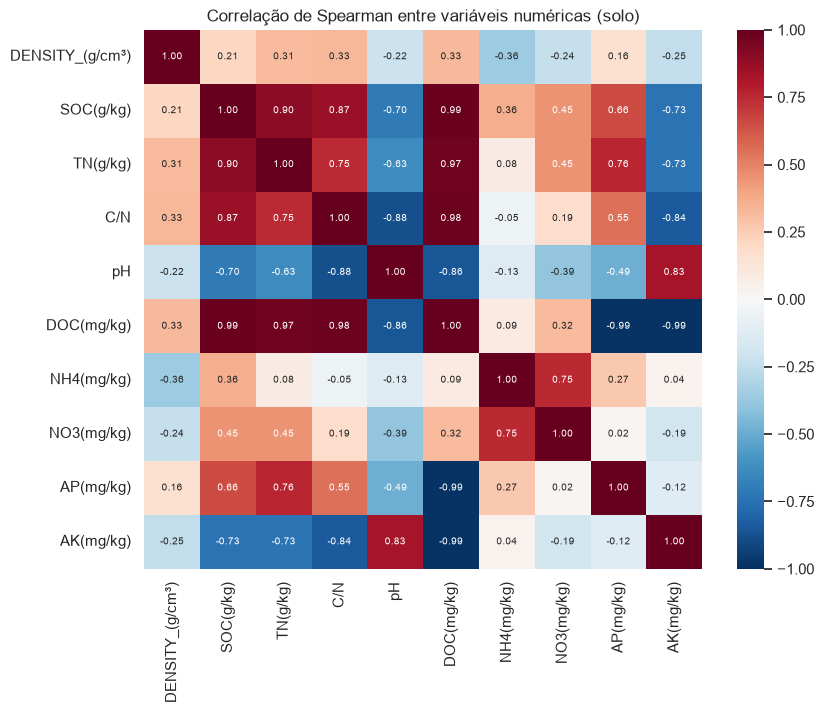

In [7]:
# colinearidade entre variáveis numéricas (amostras de solo)
d = meta.loc[meta.CONJUNTO == 'solo', NUM]
CORR = d.corr(method='spearman', min_periods=20)
fig, ax = plt.subplots(figsize=(9, 7))
sns.heatmap(CORR, annot=True, fmt='.2f', cmap='RdBu_r', center=0, vmin=-1, vmax=1, ax=ax, annot_kws={'size': 7})
ax.set_title('Correlação de Spearman entre variáveis numéricas (solo)'); savefig('01_correlacao_variaveis')

## 4. Funções de análise por variável

| Bloco | Global | Dentro do projeto (validação) |
|---|---|---|
| **Alfa** | Kruskal–Wallis (categ.) / Spearman (num.) | **Modelo misto** `métrica ~ variável + (1 | projeto)`, teste da razão de verossimilhança; nº de projetos com efeito (Kruskal por projeto) |
| **Beta** | PERMANOVA Bray–Curtis | PERMANOVA `~ projeto + variável` com **permutações dentro do projeto** |
| **Dispersão** | PERMDISP (categ.) | — |
| **PCoA** | cor por categoria / gradiente; **centróides** (média ± EP) | envfit: correlação da variável com os eixos (num.) |

In [8]:
ERROS_MISTO = []
def lrt_misto(d, y, x):
    '''LRT do efeito fixo x num modelo misto com intercepto aleatório por projeto (ML). NaN se x não varia dentro de nenhum projeto.'''
    d = d[[y, x, 'BIOPROJECT']].dropna().rename(columns={y: 'Y', x: 'X'})
    if d.groupby('BIOPROJECT').X.nunique().max() < 2: return np.nan, np.nan
    d['Y'] = (d.Y - d.Y.mean()) / d.Y.std()
    if pd.api.types.is_numeric_dtype(d.X): d['X'] = (d.X - d.X.mean()) / d.X.std(); f1 = 'Y ~ X'
    else: f1 = 'Y ~ C(X)'
    try:
        m0 = smf.mixedlm('Y ~ 1', d, groups=d.BIOPROJECT).fit(reml=False)
        m1 = smf.mixedlm(f1, d, groups=d.BIOPROJECT).fit(reml=False)
        gl = len(m1.fe_params) - 1; lr = 2 * (m1.llf - m0.llf)
        coef = m1.fe_params['X'] if 'X' in m1.fe_params else np.nan
        return coef, stats.chi2.sf(max(lr, 0), gl)
    except Exception as e:
        ERROS_MISTO.append(f'{y} ~ {x}: {type(e).__name__}: {e}')
        return np.nan, np.nan

def alfa_categorica(d, v):
    out = {}
    for mt in ['Riqueza', 'Shannon', 'FaithPD']:
        grupos = [g[mt].values for _, g in d.groupby(v) if len(g) >= 3]
        out[f'{mt}_KW_p'] = stats.kruskal(*grupos).pvalue if len(grupos) > 1 else np.nan
        out[f'{mt}_misto_p'] = lrt_misto(d, mt, v)[1]
        sig = 0; test = 0
        for _, g in d.groupby('BIOPROJECT'):
            gg = [x[mt].values for _, x in g.groupby(v) if len(x) >= 3]
            if len(gg) > 1: test += 1; sig += stats.kruskal(*gg).pvalue < .05
        out[f'{mt}_proj_sig'] = f'{sig}/{test}'
    return out

def alfa_numerica(d, v):
    out = {}
    for mt in ['Riqueza', 'Shannon', 'FaithPD']:
        x = d[[v, mt]].dropna(); r, p = stats.spearmanr(x[v], x[mt])
        out[f'{mt}_rho'] = r; out[f'{mt}_spearman_p'] = p
        coef, p2 = lrt_misto(d, mt, v); out[f'{mt}_misto_coef'] = coef; out[f'{mt}_misto_p'] = p2
    return out

def beta(d, v, ids):
    D = sub_dm(ids).data; mm = d.loc[ids]
    g = permanova(D, mm, [v], perms=PERMS)
    s = permanova(D, mm, ['BIOPROJECT', v], perms=PERMS, strata=mm.BIOPROJECT.values)
    out = dict(R2_global=g.at[v, 'R2'], p_global=g.at[v, 'p'], R2_dentro_projeto=s.at[v, 'R2'] if s.at[v, 'gl'] > 0 else np.nan,
               p_dentro_projeto=s.at[v, 'p'])
    if not pd.api.types.is_numeric_dtype(mm[v]):
        out['PERMDISP_p'] = dispersao(D, mm[v].values)[1]
    return out

def envfit(P, d, v, perms=PERMS, seed=1):
    x = d[v].dropna(); X = np.column_stack([np.ones(len(x)), P.loc[x.index, ['PC1', 'PC2']].values]); z = (x.values - x.mean()) / x.std()
    def r2(zz):
        b, *_ = np.linalg.lstsq(X, zz, rcond=None); return 1 - ((zz - X @ b) ** 2).sum() / (zz ** 2).sum(), b
    obs, b = r2(z); rng = np.random.default_rng(seed)
    cnt = 1 + sum(r2(rng.permutation(z))[0] >= obs for _ in range(perms))
    return obs, cnt / (perms + 1), b[1:] / np.linalg.norm(b[1:])

RES = {}

In [9]:
def painel_beta(ax, res):
    vals = [res['R2_global'], res['R2_dentro_projeto'] if pd.notna(res['R2_dentro_projeto']) else 0]
    ax.bar(['global', 'dentro do projeto'], vals, color=['#9aa5b1', '#2e86c1'])
    for i, (r2, p) in enumerate([(res['R2_global'], res['p_global']), (res['R2_dentro_projeto'], res['p_dentro_projeto'])]):
        ax.text(i, (r2 if pd.notna(r2) else 0) + .005, 'não testável\n(constante no projeto)' if pd.isna(r2) else f'R²={r2:.3f}\np={p:.3f}', ha='center', fontsize=9)
    ax.set_ylabel('R² PERMANOVA (Bray–Curtis)'); ax.set_ylim(0, max(v for v in vals if pd.notna(v)) * 1.35 + .01)

def fig_categorica(v, d, P, ve, res, nome):
    ordem = d[v].value_counts().index.tolist()
    pal = dict(zip(ordem, sns.color_palette('tab20', len(ordem))))
    fig = plt.figure(figsize=(22, 13)); gs = fig.add_gridspec(2, 3, hspace=.35, wspace=.3)
    m = d.groupby(v)[['Shannon', 'Riqueza']].agg(['mean', 'sem', 'size']).reindex(ordem)
    ax = fig.add_subplot(gs[0, 0])    # (a) barras Shannon
    ax.barh(range(len(ordem)), m[('Shannon', 'mean')], xerr=m[('Shannon', 'sem')], color=[pal[o] for o in ordem], capsize=3)
    ax.set_yticks(range(len(ordem)), [f'{o} (n={int(n)})' for o, n in zip(ordem, m[('Shannon', 'size')])], fontsize=8)
    ax.invert_yaxis(); ax.set_xlabel('Shannon (média ± EP)')
    ax.set_title(f"(a) Barras — Shannon | KW p={res['Shannon_KW_p']:.2g}", fontsize=10)
    ax = fig.add_subplot(gs[0, 1])    # (b) barras riqueza
    ax.barh(range(len(ordem)), m[('Riqueza', 'mean')], xerr=m[('Riqueza', 'sem')], color=[pal[o] for o in ordem], capsize=3)
    ax.set_yticks(range(len(ordem)), ordem, fontsize=8); ax.invert_yaxis(); ax.set_xlabel('Riqueza de ASVs (média ± EP)')
    ax.set_title(f"(b) Barras — Riqueza | KW p={res['Riqueza_KW_p']:.2g}; misto p={res['Riqueza_misto_p']:.2g}", fontsize=10)
    ax = fig.add_subplot(gs[0, 2])    # (c) médias por projeto
    sns.pointplot(data=d, x=v, y='Shannon', hue='BIOPROJECT', order=ordem, dodge=.5, errorbar=('ci', 95), ax=ax, markersize=4, linewidth=1)
    ax.tick_params(axis='x', rotation=60, labelsize=7); ax.legend(fontsize=6, ncol=2); ax.set_xlabel('')
    ax.set_title(f"(c) Médias (IC95%) por projeto — Shannon\nmisto p={res['Shannon_misto_p']:.2g}; projetos com efeito {res['Shannon_proj_sig']}", fontsize=10)
    ax = fig.add_subplot(gs[1, 0])    # (d) PCoA
    dd = P.join(d[[v, 'BIOPROJECT']], how='inner')
    sns.scatterplot(data=dd, x='PC1', y='PC2', hue=v, hue_order=ordem, palette=pal, s=16, alpha=.8, ax=ax, legend=False)
    ax.set_xlabel(f'PC1 ({ve[0]:.1f}%)'); ax.set_ylabel(f'PC2 ({ve[1]:.1f}%)'); ax.set_title('(d) PCoA Bray–Curtis — dispersão das amostras', fontsize=10)
    ax = fig.add_subplot(gs[1, 1])    # (e) centróides
    c = dd.groupby(v)[['PC1', 'PC2']].agg(['mean', 'sem']).reindex(ordem)
    for o in ordem:
        ax.errorbar(c.at[o, ('PC1', 'mean')], c.at[o, ('PC2', 'mean')], xerr=c.at[o, ('PC1', 'sem')], yerr=c.at[o, ('PC2', 'sem')],
                    fmt='o', color=pal[o], ms=9, capsize=3, label=o)
    ax.legend(fontsize=7, bbox_to_anchor=(1, 1)); ax.set_xlabel('PC1'); ax.set_ylabel('PC2'); ax.set_title('(e) Média dos eixos da PCoA (centróide ± EP)', fontsize=10)
    ax = fig.add_subplot(gs[1, 2]); painel_beta(ax, res)   # (f)
    ax.set_title(f"(f) Beta — global × dentro do projeto | PERMDISP p={res.get('PERMDISP_p', np.nan):.2g}", fontsize=10)
    fig.suptitle(f'{v}   (V de Cramér com projeto = {CONF.at[v, "associacao_com_projeto"]:.2f})', fontsize=16, weight='bold'); savefig(nome)

def fig_numerica(v, d, P, ve, res, nome):
    dd = d[d[v].notna()]
    pal = dict(zip(sorted(dd.BIOPROJECT.unique()), sns.color_palette('tab10', dd.BIOPROJECT.nunique())))
    fig = plt.figure(figsize=(22, 12)); gs = fig.add_gridspec(2, 3, hspace=.35, wspace=.25)
    for k, mt in enumerate(['Shannon', 'Riqueza']):     # (a)(b) dispersão
        ax = fig.add_subplot(gs[0, k])
        sns.scatterplot(data=dd, x=v, y=mt, hue='BIOPROJECT', s=18, alpha=.7, ax=ax, legend=(k == 0), palette=pal)
        sns.regplot(data=dd, x=v, y=mt, scatter=False, ax=ax, color='k', line_kws={'lw': 1, 'ls': '--'})
        ax.set_title(f"({'ab'[k]}) Dispersão {mt} | ρ={res[f'{mt}_rho']:.2f} (p={res[f'{mt}_spearman_p']:.2g}); misto p={res[f'{mt}_misto_p']:.2g}", fontsize=10)
        if k == 0: ax.legend(fontsize=6)
    ax = fig.add_subplot(gs[0, 2])                       # (c) médias por valor distinto
    g = dd.groupby([v, 'BIOPROJECT']).Shannon.agg(['mean', 'sem']).reset_index().sort_values(v)
    for _, r in g.iterrows():
        ax.errorbar(r[v], r['mean'], yerr=r['sem'], fmt='o', color=pal[r.BIOPROJECT], capsize=3, ms=6)
    ax.set_xlabel(v); ax.set_ylabel('Shannon (média ± EP)'); ax.set_title(f'(c) Médias por valor distinto (n valores = {dd[v].nunique()})', fontsize=10)
    ax = fig.add_subplot(gs[1, 0]); pp = P.join(dd[[v]], how='inner')    # (d) PCoA + envfit
    sc = ax.scatter(pp.PC1, pp.PC2, c=pp[v], cmap='viridis', s=14); plt.colorbar(sc, ax=ax, label=v)
    s = np.abs(pp[['PC1', 'PC2']]).max().min() * .8; vec = res['envfit_dir'] * s * np.sqrt(res['envfit_r2'])
    ax.arrow(0, 0, vec[0], vec[1], color='red', width=s * .01)
    ax.set_xlabel(f'PC1 ({ve[0]:.1f}%)'); ax.set_ylabel(f'PC2 ({ve[1]:.1f}%)'); ax.set_title(f"(d) PCoA + envfit | r²={res['envfit_r2']:.2f}, p={res['envfit_p']:.3f}", fontsize=10)
    ax = fig.add_subplot(gs[1, 1])                       # (e) PC1 × variável
    sns.scatterplot(data=pp.join(dd.BIOPROJECT), x=v, y='PC1', hue='BIOPROJECT', s=16, ax=ax, legend=False, palette=pal)
    r, p = stats.spearmanr(pp[v], pp.PC1); ax.set_title(f'(e) Dispersão PC1 × {v} | ρ={r:.2f}', fontsize=10)
    ax = fig.add_subplot(gs[1, 2]); painel_beta(ax, res); ax.set_title('(f) Beta — global × dentro do projeto', fontsize=10)
    fig.suptitle(f'{v}   (η² entre projetos = {CONF.at[v, "associacao_com_projeto"]:.2f})', fontsize=16, weight='bold'); savefig(nome)

## 5. Variáveis categóricas

### 5.1 `SOIL_FRACTION`
Todas as 553 amostras (inclui intestino e enriquecimento).

,Riqueza_KW_p,Riqueza_misto_p,Riqueza_proj_sig,Shannon_KW_p,Shannon_misto_p,Shannon_proj_sig,FaithPD_KW_p,FaithPD_misto_p,FaithPD_proj_sig,R2_global,p_global,R2_dentro_projeto,p_dentro_projeto,PERMDISP_p
SOIL_FRACTION,0.0,0.0,4/5,0.0,0.0,4/5,0.0,0.0,4/5,0.250546,0.001,0.083605,0.001,0.0


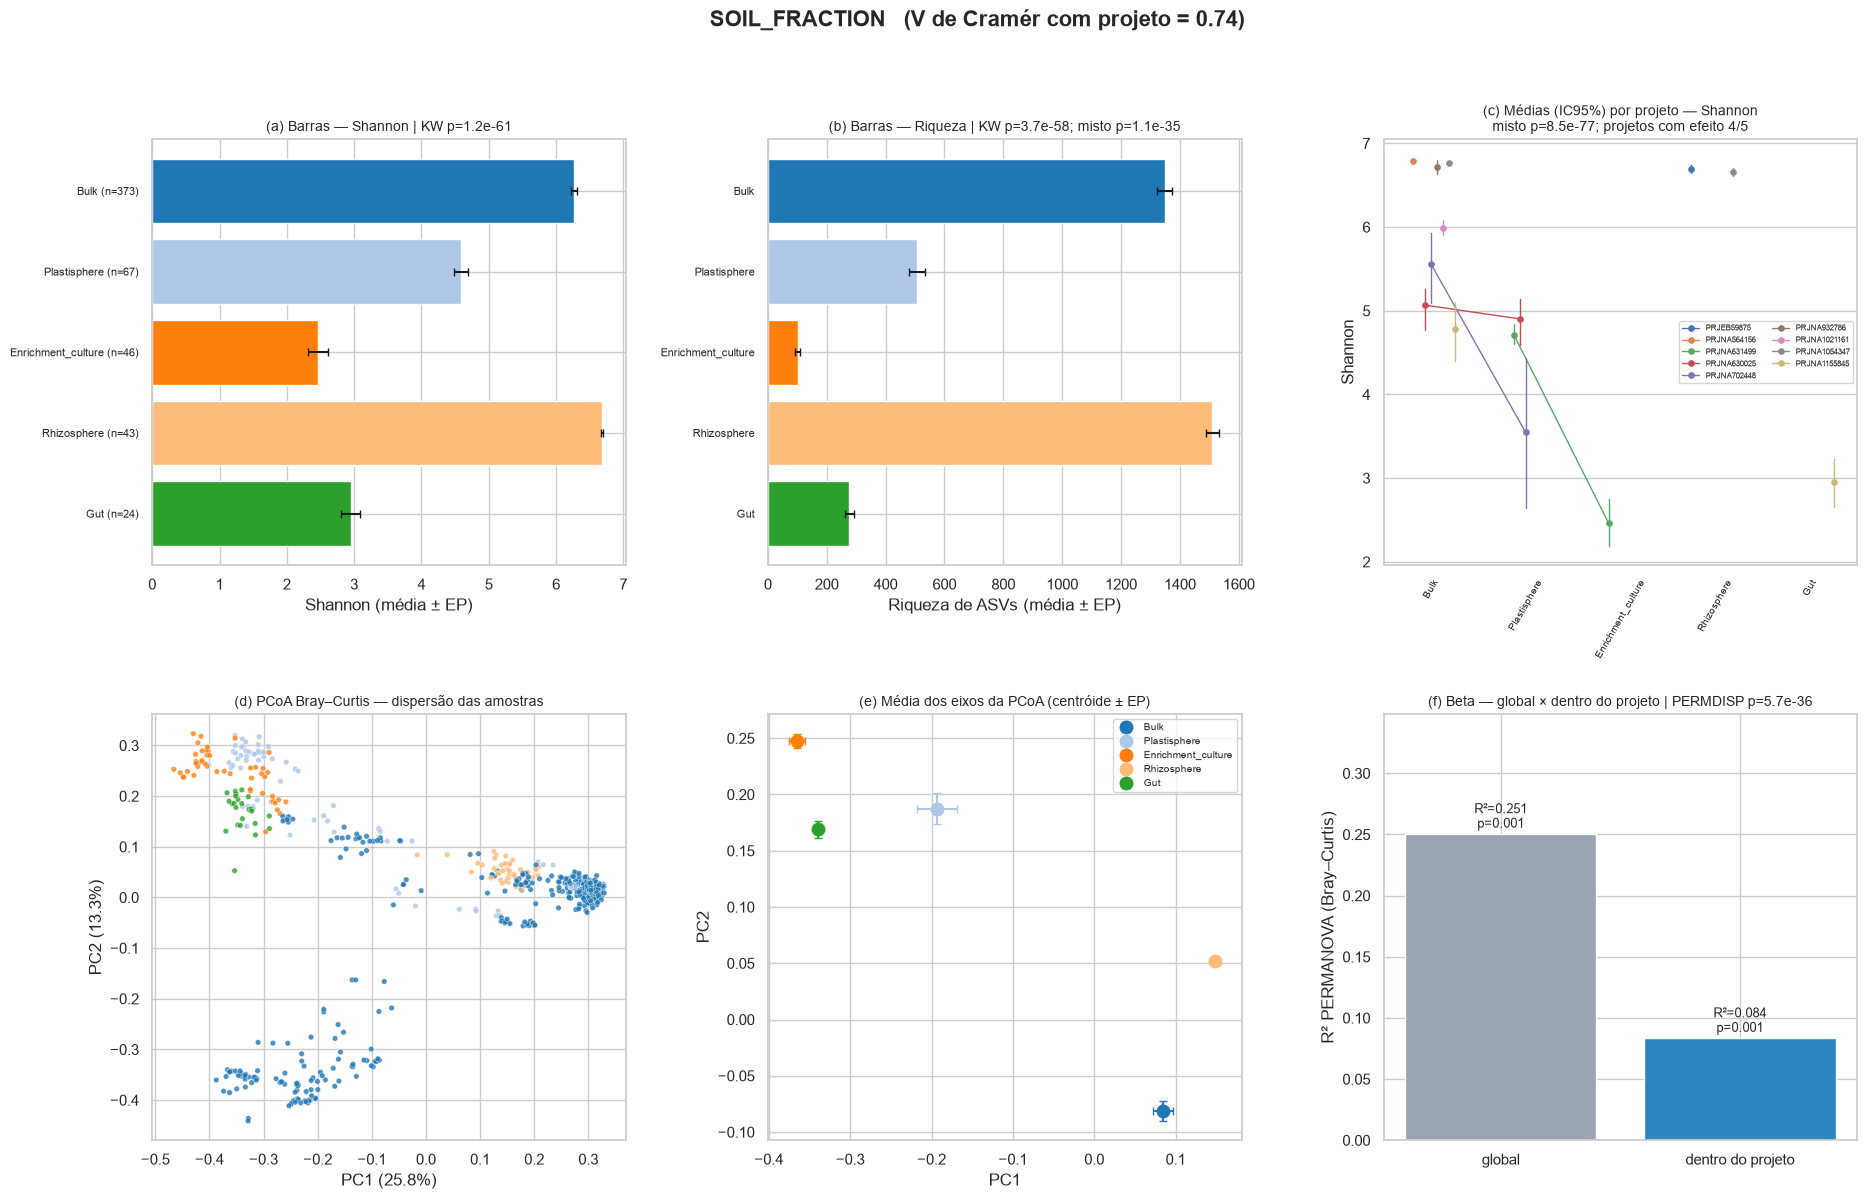

In [10]:
v = 'SOIL_FRACTION'
d = A if v == 'SOIL_FRACTION' else A[A.CONJUNTO == 'solo']
P, ve = (PC, VE) if v == 'SOIL_FRACTION' else (PCs, VEs)
d = d[d[v].notna()]
res = {**alfa_categorica(d, v), **beta(d, v, list(d.index))}
RES[v] = res
display(pd.Series(res).to_frame(v).T)
if ERROS_MISTO: print(ERROS_MISTO[-3:])
fig_categorica(v, d, P, ve, res, '01_cat_soil_fraction')

### 5.2 `POLYMER_TYPE`
Amostras de solo. `Controle (NONE)` = sem plástico; `NA (papel)` = mulch de celulose (Weedguard).

,Riqueza_KW_p,Riqueza_misto_p,Riqueza_proj_sig,Shannon_KW_p,Shannon_misto_p,Shannon_proj_sig,FaithPD_KW_p,FaithPD_misto_p,FaithPD_proj_sig,R2_global,p_global,R2_dentro_projeto,p_dentro_projeto,PERMDISP_p
POLYMER_TYPE,0.0,0.000037,4/9,0.0,0.0,3/9,0.0,0.000005,3/9,0.270831,0.001,0.033597,0.001,0.0


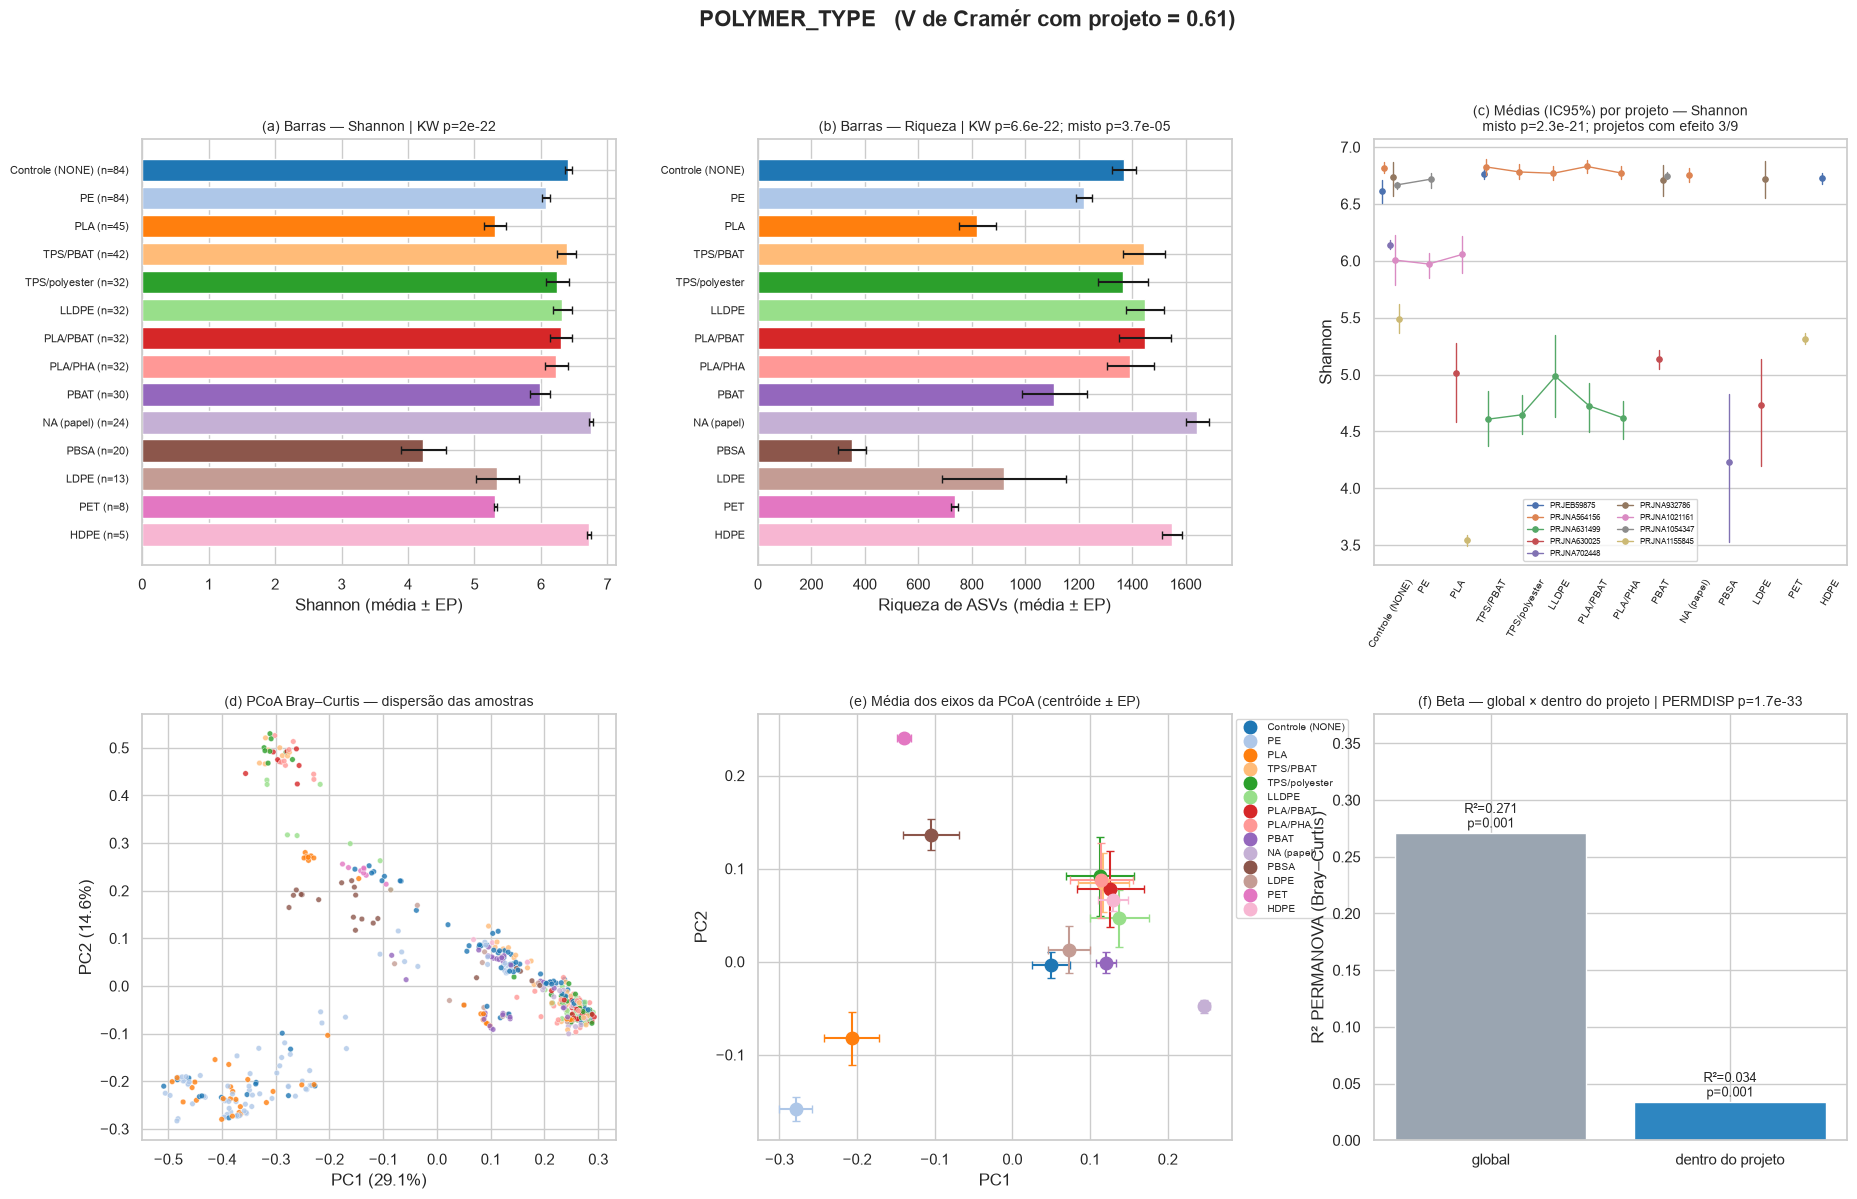

In [11]:
v = 'POLYMER_TYPE'
d = A if v == 'SOIL_FRACTION' else A[A.CONJUNTO == 'solo']
P, ve = (PC, VE) if v == 'SOIL_FRACTION' else (PCs, VEs)
d = d[d[v].notna()]
res = {**alfa_categorica(d, v), **beta(d, v, list(d.index))}
RES[v] = res
display(pd.Series(res).to_frame(v).T)
if ERROS_MISTO: print(ERROS_MISTO[-3:])
fig_categorica(v, d, P, ve, res, '02_cat_polymer_type')

### 5.3 `BIODEGRADABLE`
Amostras de solo. `NA (sem plástico)` = controles e papel.

,Riqueza_KW_p,Riqueza_misto_p,Riqueza_proj_sig,Shannon_KW_p,Shannon_misto_p,Shannon_proj_sig,FaithPD_KW_p,FaithPD_misto_p,FaithPD_proj_sig,R2_global,p_global,R2_dentro_projeto,p_dentro_projeto,PERMDISP_p
BIODEGRADABLE,0.000108,0.019955,4/9,0.000014,0.000072,3/9,0.002295,0.020802,3/9,0.053693,0.001,0.005384,0.001,0.0


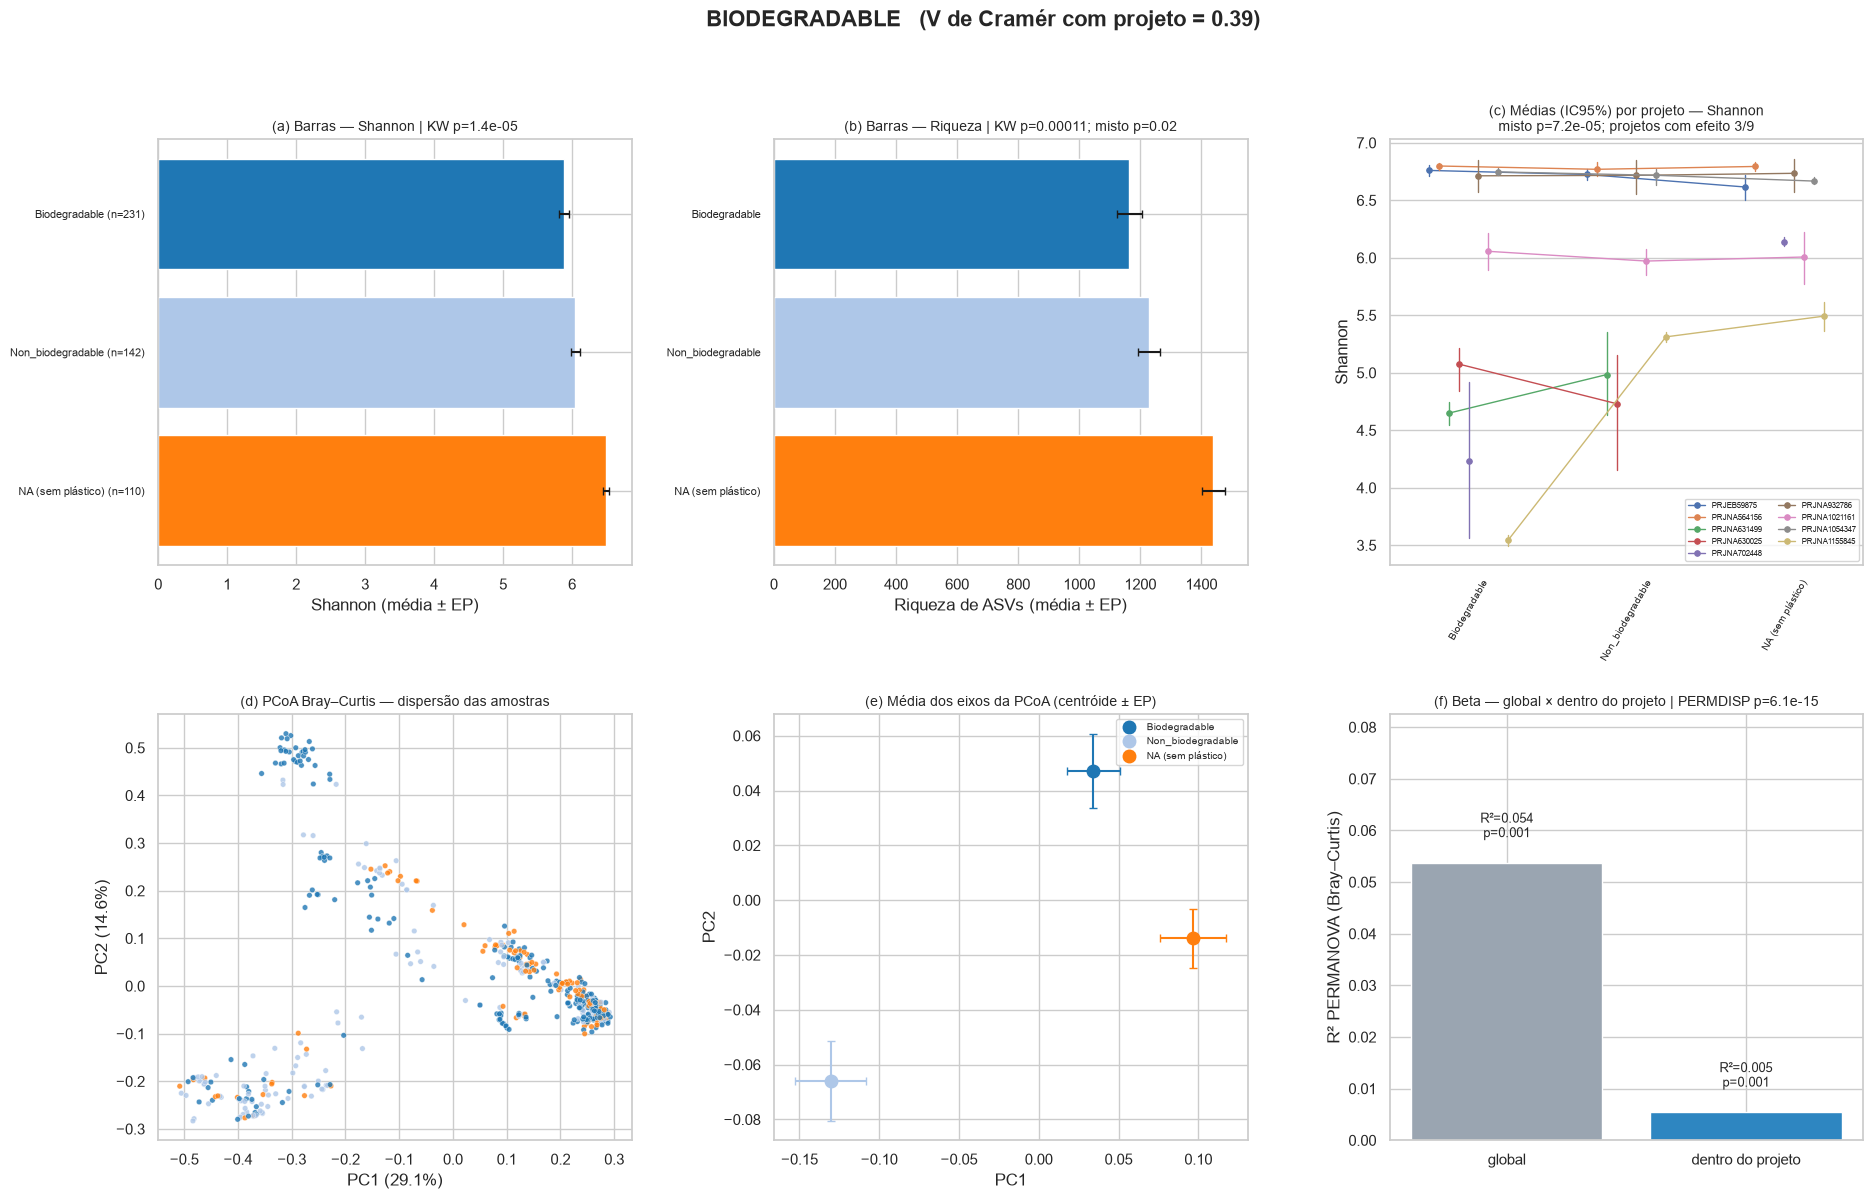

In [12]:
v = 'BIODEGRADABLE'
d = A if v == 'SOIL_FRACTION' else A[A.CONJUNTO == 'solo']
P, ve = (PC, VE) if v == 'SOIL_FRACTION' else (PCs, VEs)
d = d[d[v].notna()]
res = {**alfa_categorica(d, v), **beta(d, v, list(d.index))}
RES[v] = res
display(pd.Series(res).to_frame(v).T)
if ERROS_MISTO: print(ERROS_MISTO[-3:])
fig_categorica(v, d, P, ve, res, '03_cat_biodegradable')

### 5.4 `POLYMER_SIZE`
Amostras de solo. A coluna mistura espessura de filme, tamanho de pedaço e diâmetro de partícula (µm); cada categoria praticamente identifica um estudo, por isso a validação dentro do projeto é essencial.

,Riqueza_KW_p,Riqueza_misto_p,Riqueza_proj_sig,Shannon_KW_p,Shannon_misto_p,Shannon_proj_sig,FaithPD_KW_p,FaithPD_misto_p,FaithPD_proj_sig,R2_global,p_global,R2_dentro_projeto,p_dentro_projeto,PERMDISP_p
POLYMER_SIZE,0.0,0.0,4/8,0.0,0.0,4/8,0.0,0.0,3/8,0.384268,0.001,0.026896,0.001,0.0


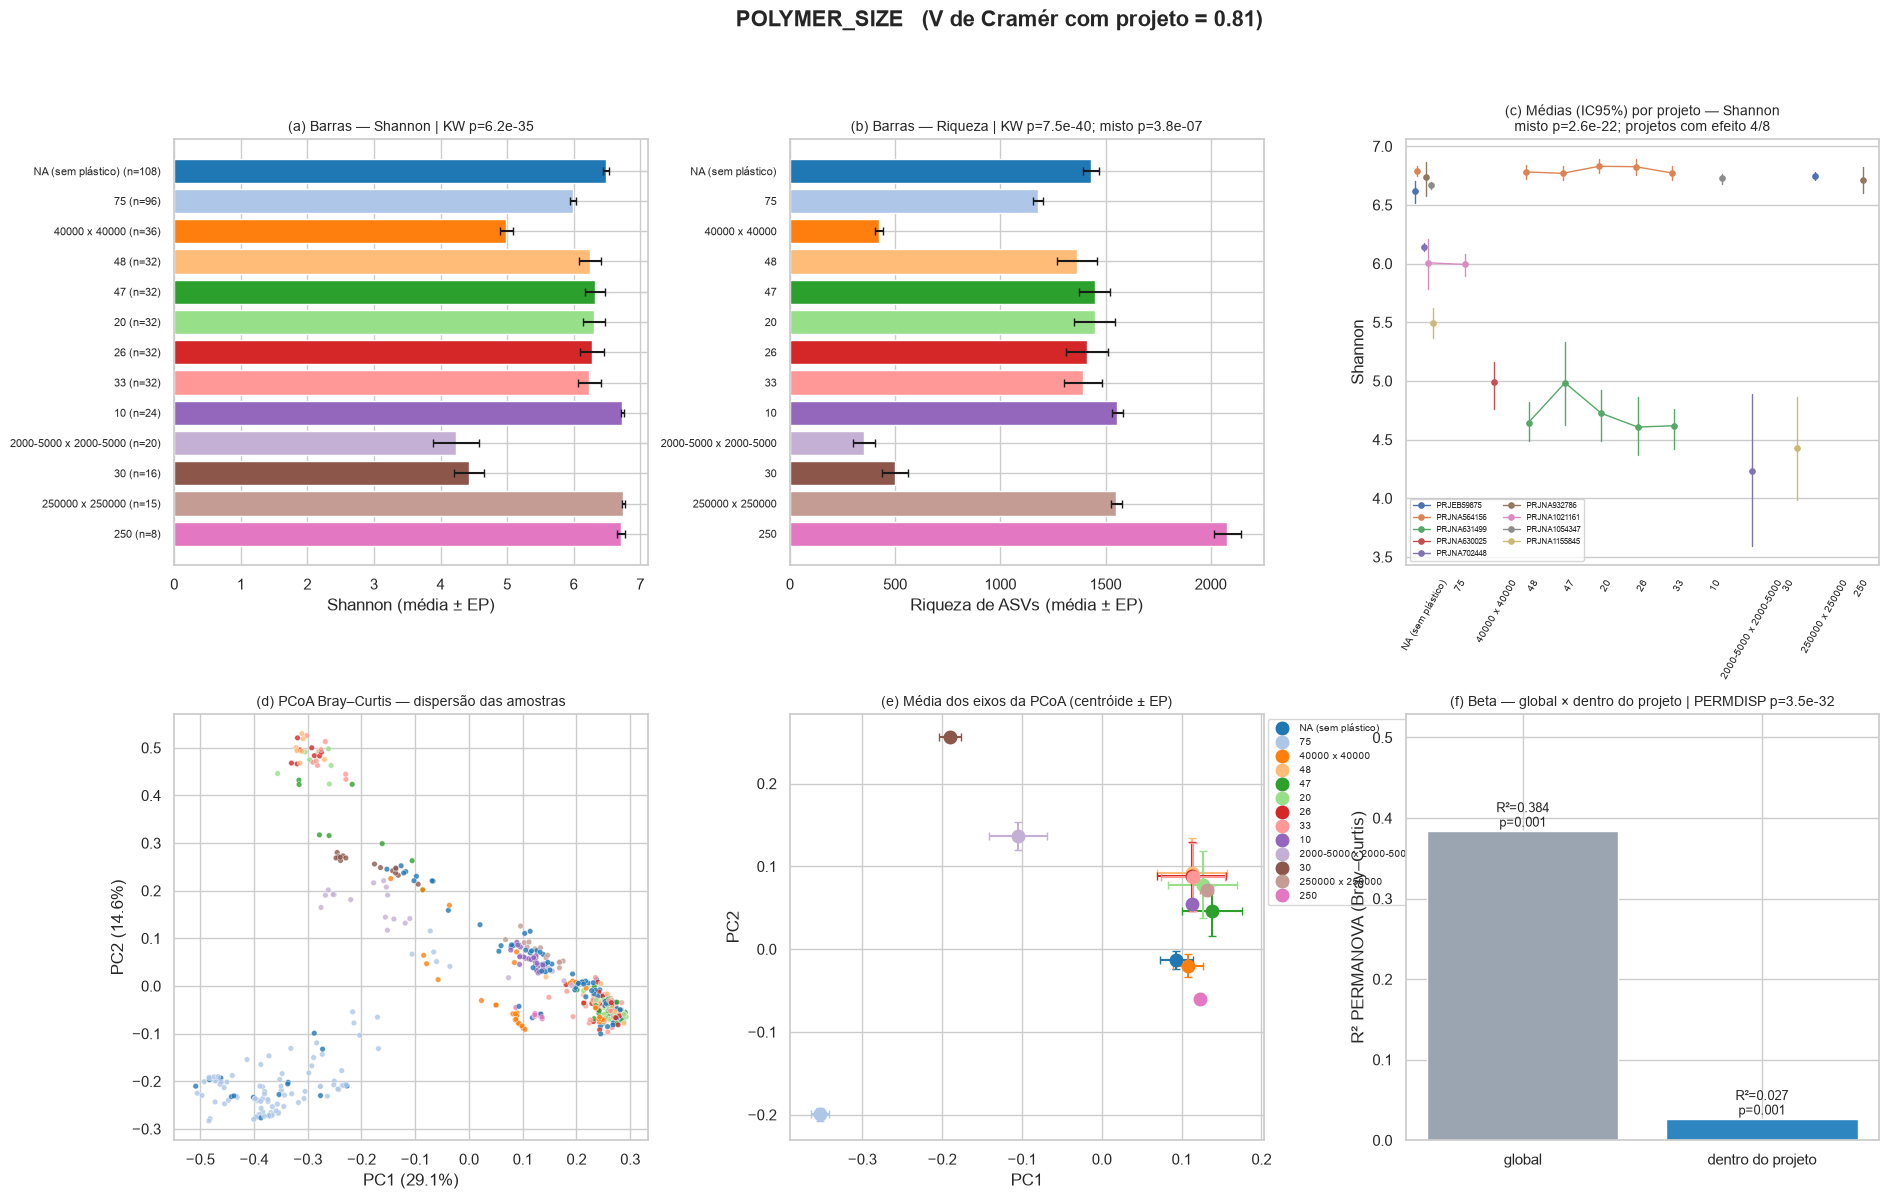

In [13]:
v = 'POLYMER_SIZE'
d = A if v == 'SOIL_FRACTION' else A[A.CONJUNTO == 'solo']
P, ve = (PC, VE) if v == 'SOIL_FRACTION' else (PCs, VEs)
d = d[d[v].notna()]
res = {**alfa_categorica(d, v), **beta(d, v, list(d.index))}
RES[v] = res
display(pd.Series(res).to_frame(v).T)
if ERROS_MISTO: print(ERROS_MISTO[-3:])
fig_categorica(v, d, P, ve, res, '04_cat_polymer_size')

### 5.5 PCoA dentro de cada projeto (ASV, Bray–Curtis)
Dentro de um estudo, região do 16S, solo e laboratório são os mesmos: é aqui que o efeito do plástico aparece "limpo".

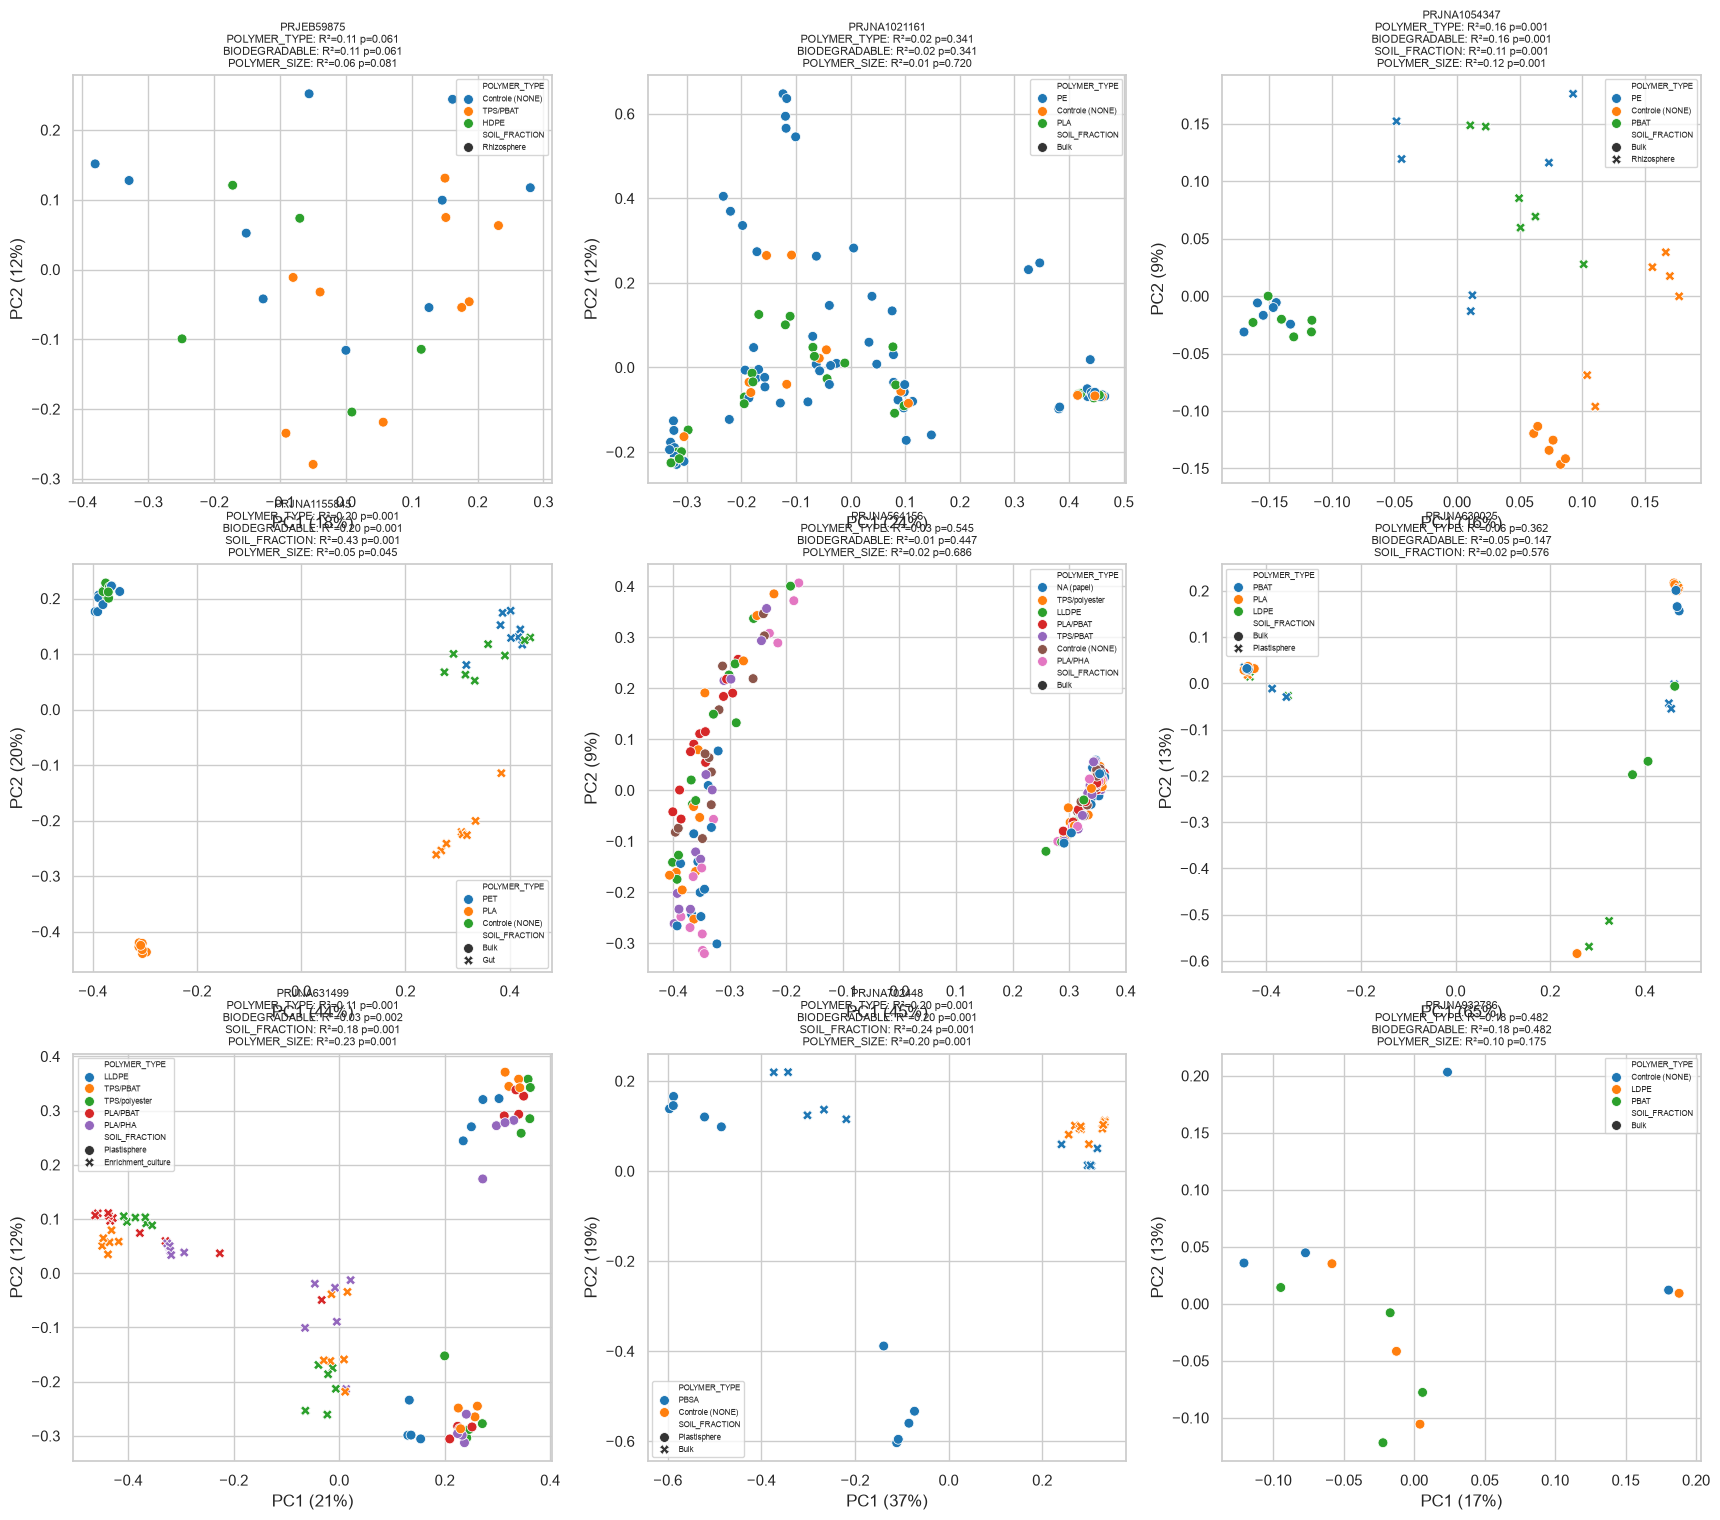

R2                                                     p                                        
variavel     BIODEGRADABLE POLYMER_SIZE POLYMER_TYPE SOIL_FRACTION BIODEGRADABLE POLYMER_SIZE POLYMER_TYPE SOIL_FRACTION
projeto                                                                                                                 
PRJEB59875           0.111        0.057        0.111           NaN         0.061        0.081        0.061           NaN
PRJNA1021161         0.019        0.007        0.019           NaN         0.341        0.720        0.341           NaN
PRJNA1054347         0.158        0.116        0.158         0.111         0.001        0.001        0.001         0.001
PRJNA1155845         0.203        0.051        0.203         0.434         0.001        0.045        0.001         0.001
PRJNA564156          0.011        0.025        0.033           NaN         0.447        0.686        0.545           NaN
PRJNA630025          0.051          NaN        0.059         0.020         0.147          NaN        0.362         0.576
PRJNA631499          0.033        0.231        0.109         0.179         0.002        0.001        0.001         0.001
PRJNA702448          0.202        0.202        0.202         0.244         0.001        0.001        0.001         0.001
PRJNA932786          0.181        0.100        0.181           NaN         0.482        0.175        0.482           NaN

In [14]:
projs = [p for p, g in meta.groupby('BIOPROJECT') if len(g) >= 12]
fig, axes = plt.subplots(3, 3, figsize=(21, 18)); rows = []
for ax, pj in zip(axes.flat, projs):
    s = list(meta.index[meta.BIOPROJECT == pj]); X = rare[s]; X = X.loc[X.sum(1) > 0]
    dm = beta_diversity('braycurtis', X.T.values, ids=s); o = pcoa(dm, number_of_dimensions=2)
    dd = o.samples.set_axis(['PC1', 'PC2'], axis=1).join(meta[['POLYMER_TYPE', 'SOIL_FRACTION']])
    sns.scatterplot(data=dd, x='PC1', y='PC2', hue='POLYMER_TYPE', style='SOIL_FRACTION', s=50, ax=ax, palette='tab10')
    pe = o.proportion_explained.values[:2] * 100; mm = meta.loc[s]
    for v in ['POLYMER_TYPE', 'BIODEGRADABLE', 'SOIL_FRACTION', 'POLYMER_SIZE']:
        if mm[v].nunique() > 1:
            r = permanova(dm.data, mm, [v], perms=PERMS); rows.append(dict(projeto=pj, variavel=v, R2=r.at[v, 'R2'], p=r.at[v, 'p']))
    t = '\n'.join(f"{x['variavel']}: R²={x['R2']:.2f} p={x['p']:.3f}" for x in rows if x['projeto'] == pj)
    ax.set_title(f'{pj}\n{t}', fontsize=8); ax.set_xlabel(f'PC1 ({pe[0]:.0f}%)'); ax.set_ylabel(f'PC2 ({pe[1]:.0f}%)'); ax.legend(fontsize=6)
savefig('05_pcoa_por_projeto')
PROJ = pd.DataFrame(rows); PROJ.round(4).to_csv(TAB / '05_permanova_por_projeto.csv', index=False)
PROJ.pivot(index='projeto', columns='variavel', values=['R2', 'p']).round(3)

## 6. Variáveis numéricas
Amostras de solo. Para cada variável: dispersão alfa × variável, gráfico de médias por valor distinto, PCoA com gradiente e seta
**envfit**, PC1 × variável e R² da PERMANOVA. Muitas destas variáveis são **médias de artigo** (um valor por local ou tratamento),
então o *n* efetivo é o número de valores distintos, não o número de amostras.


=== DENSITY_(g/cm³): n=343, valores distintos=8, projetos=9


,Riqueza_rho,Riqueza_spearman_p,Riqueza_misto_coef,Riqueza_misto_p,Shannon_rho,Shannon_spearman_p,Shannon_misto_coef,Shannon_misto_p,FaithPD_rho,FaithPD_spearman_p,FaithPD_misto_coef,FaithPD_misto_p,R2_global,p_global,R2_dentro_projeto,p_dentro_projeto,envfit_r2,envfit_p
DENSITY_(g/cm³),-0.133853,0.013097,0.01972,0.409784,-0.100669,0.062555,0.040564,0.223543,-0.163415,0.002398,0.021182,0.424576,0.038806,0.001,0.002106,0.009,0.166428,0.001


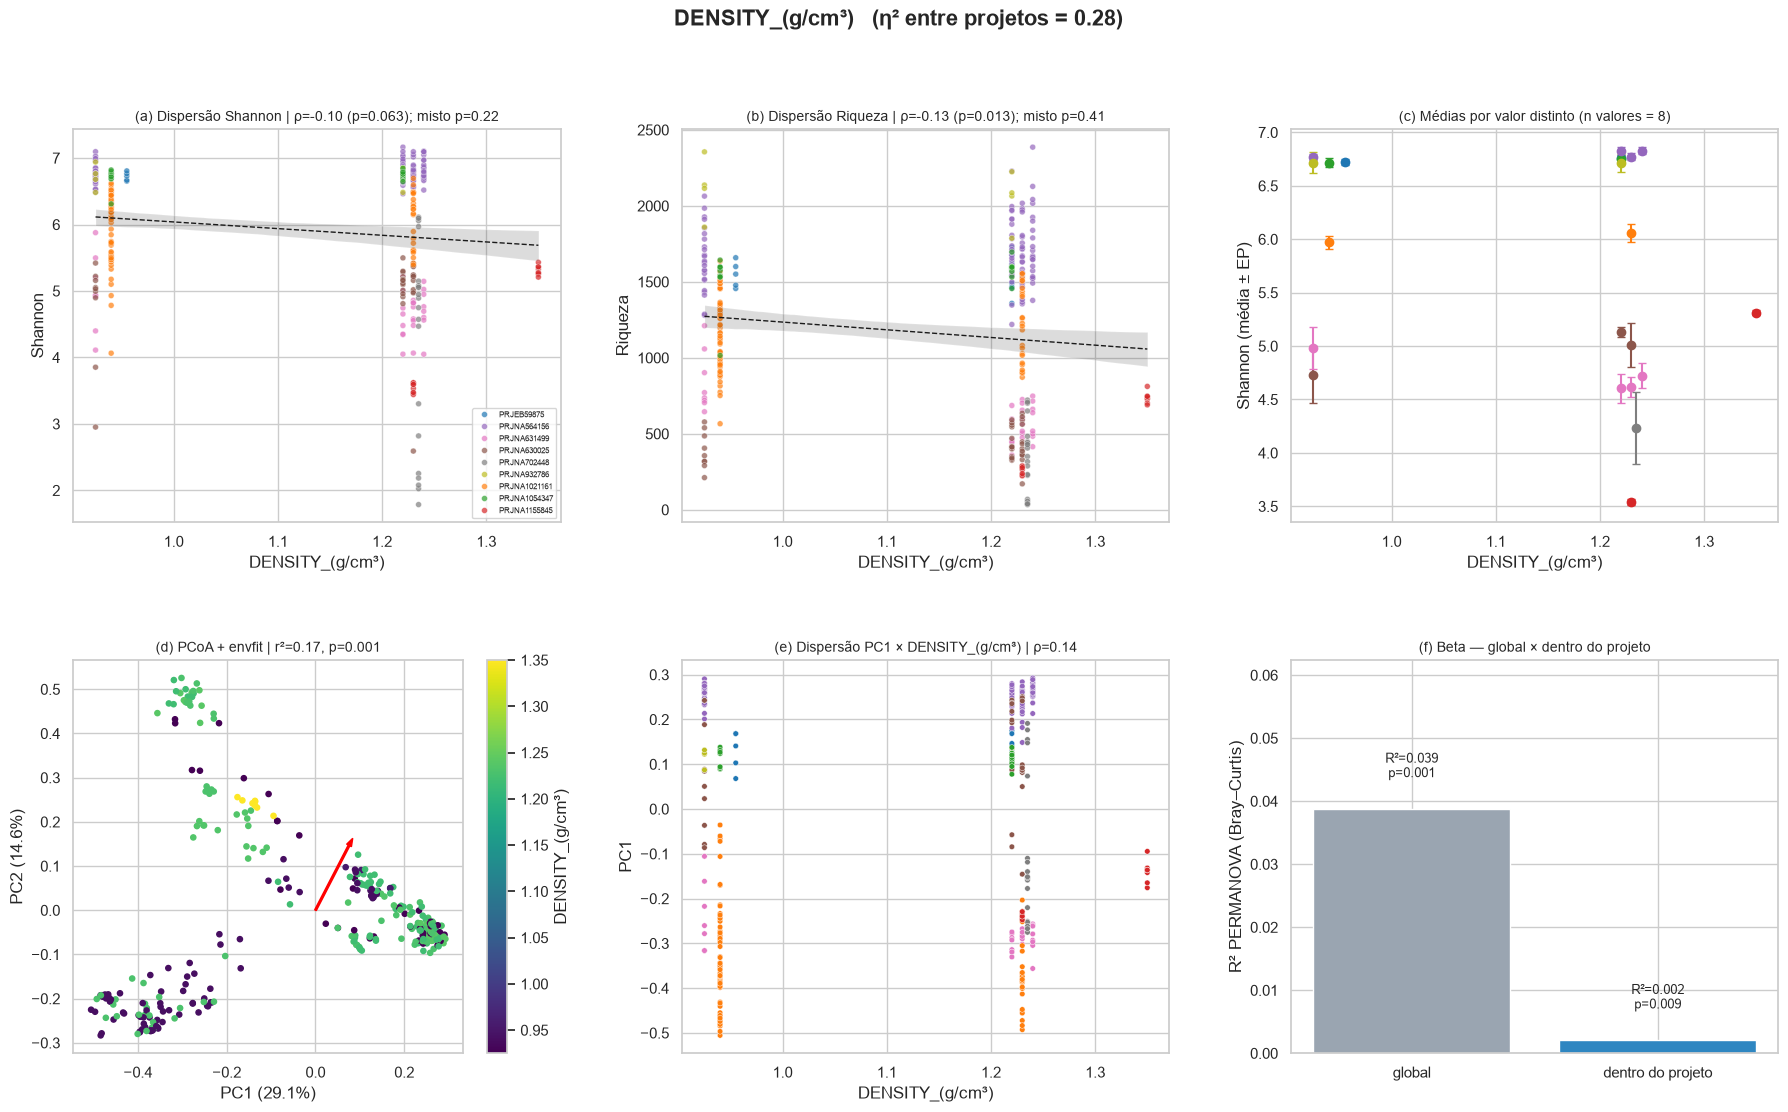


=== SOC(g/kg): n=354, valores distintos=18, projetos=8


,Riqueza_rho,Riqueza_spearman_p,Riqueza_misto_coef,Riqueza_misto_p,Shannon_rho,Shannon_spearman_p,Shannon_misto_coef,Shannon_misto_p,FaithPD_rho,FaithPD_spearman_p,FaithPD_misto_coef,FaithPD_misto_p,R2_global,p_global,R2_dentro_projeto,p_dentro_projeto,envfit_r2,envfit_p
SOC(g/kg),0.182695,0.000552,-0.153402,0.000589,0.292811,1.986042e-08,-0.124658,0.073279,0.023495,0.65954,-0.231154,0.000008,0.142284,0.001,0.025358,0.001,0.431602,0.001


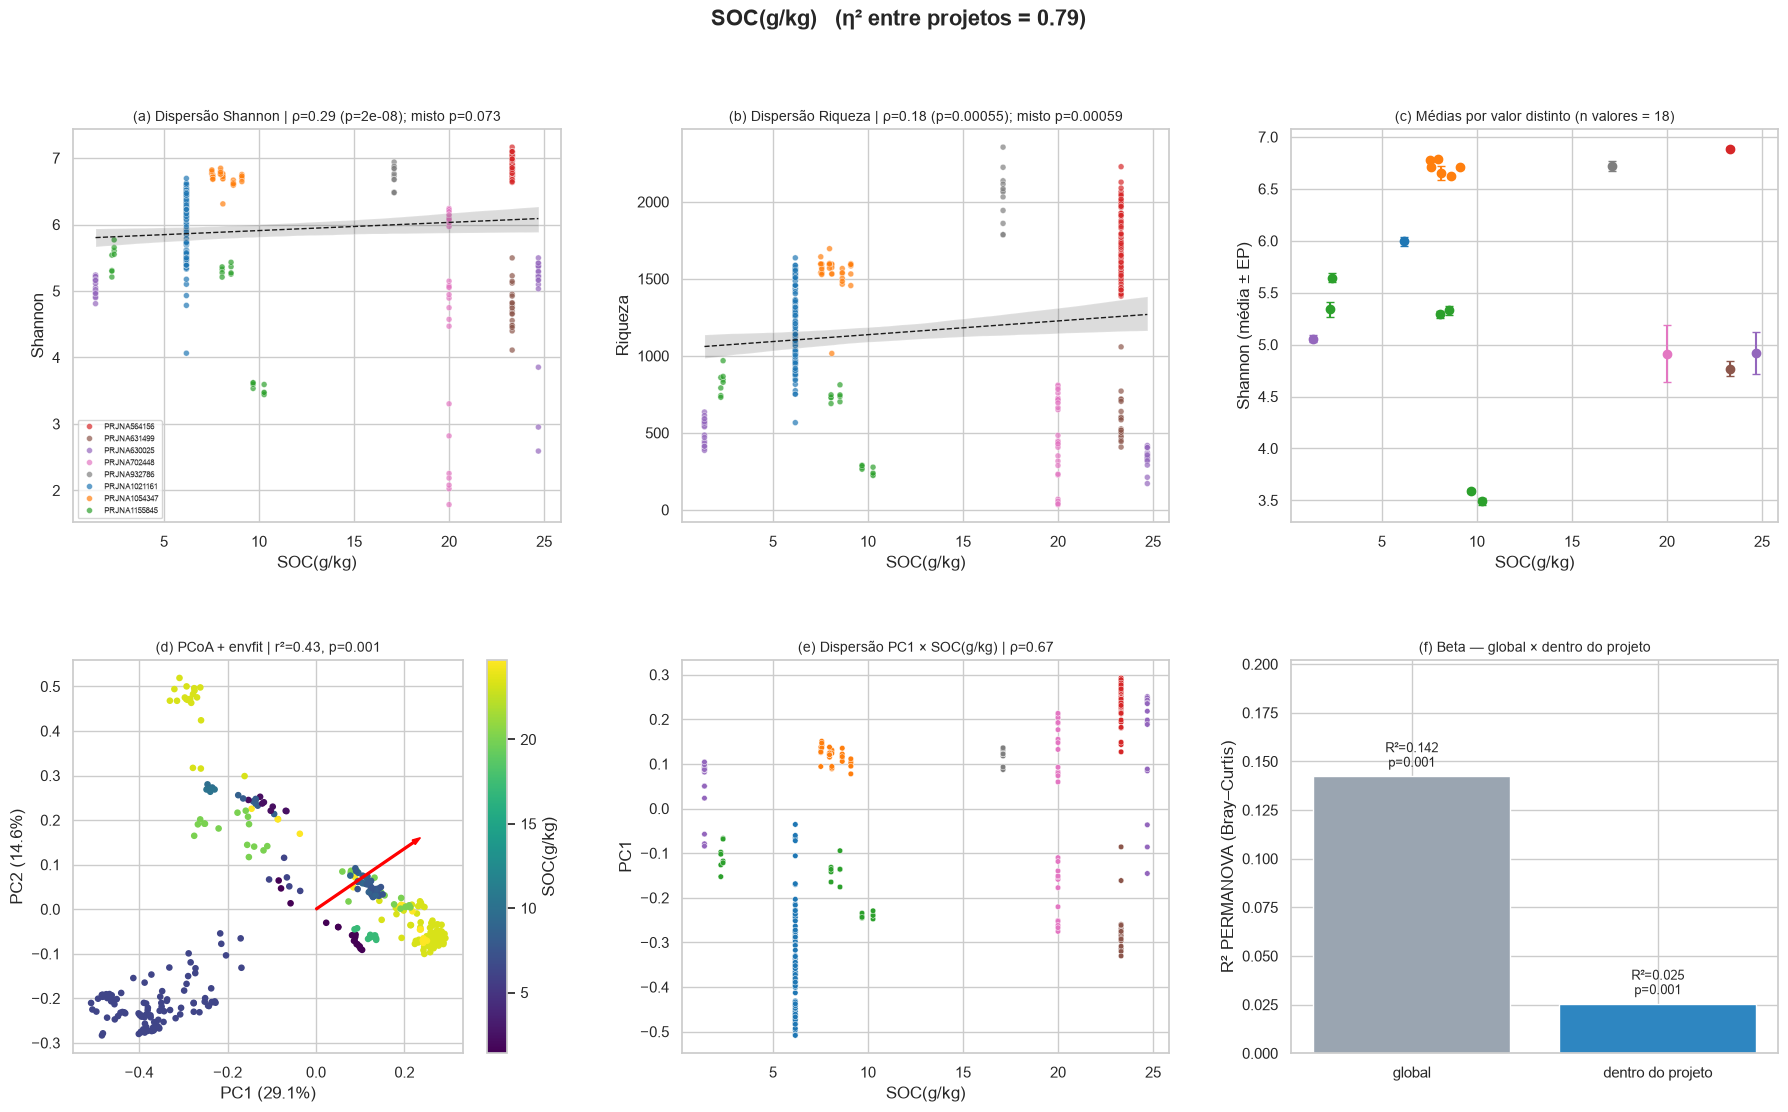


=== TN(g/kg): n=317, valores distintos=11, projetos=6


,Riqueza_rho,Riqueza_spearman_p,Riqueza_misto_coef,Riqueza_misto_p,Shannon_rho,Shannon_spearman_p,Shannon_misto_coef,Shannon_misto_p,FaithPD_rho,FaithPD_spearman_p,FaithPD_misto_coef,FaithPD_misto_p,R2_global,p_global,R2_dentro_projeto,p_dentro_projeto,envfit_r2,envfit_p
TN(g/kg),-0.010152,0.857125,-0.14827,0.000013,0.122627,0.029041,-0.353755,2.464527e-12,-0.175332,0.001726,-0.254278,9.992124e-11,0.073309,0.001,0.024521,0.001,0.193913,0.001


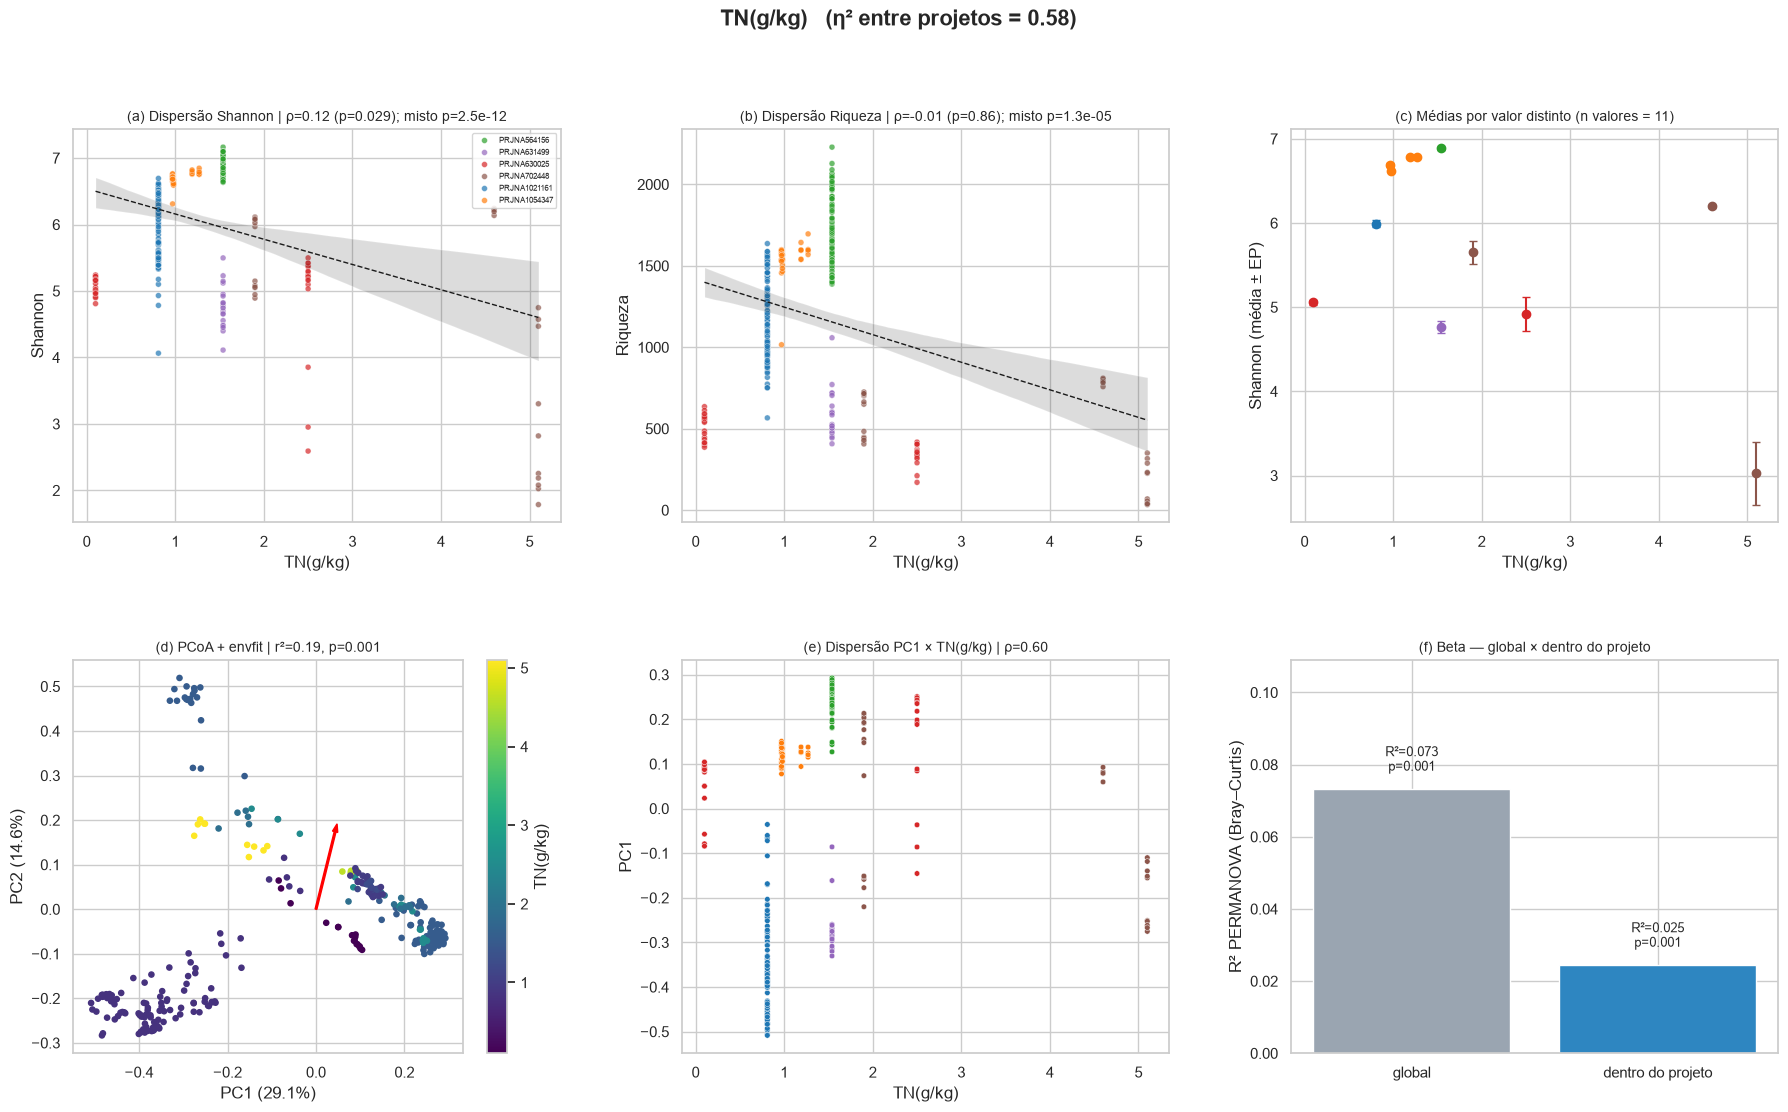


=== C/N: n=300, valores distintos=10, projetos=6


,Riqueza_rho,Riqueza_spearman_p,Riqueza_misto_coef,Riqueza_misto_p,Shannon_rho,Shannon_spearman_p,Shannon_misto_coef,Shannon_misto_p,FaithPD_rho,FaithPD_spearman_p,FaithPD_misto_coef,FaithPD_misto_p,R2_global,p_global,R2_dentro_projeto,p_dentro_projeto,envfit_r2,envfit_p
C/N,0.2302,0.000057,-0.131709,0.473992,0.311837,3.452203e-08,-0.124505,0.607476,0.054804,0.344162,-0.140541,0.491852,0.190116,0.001,0.001971,0.001,0.465245,0.001


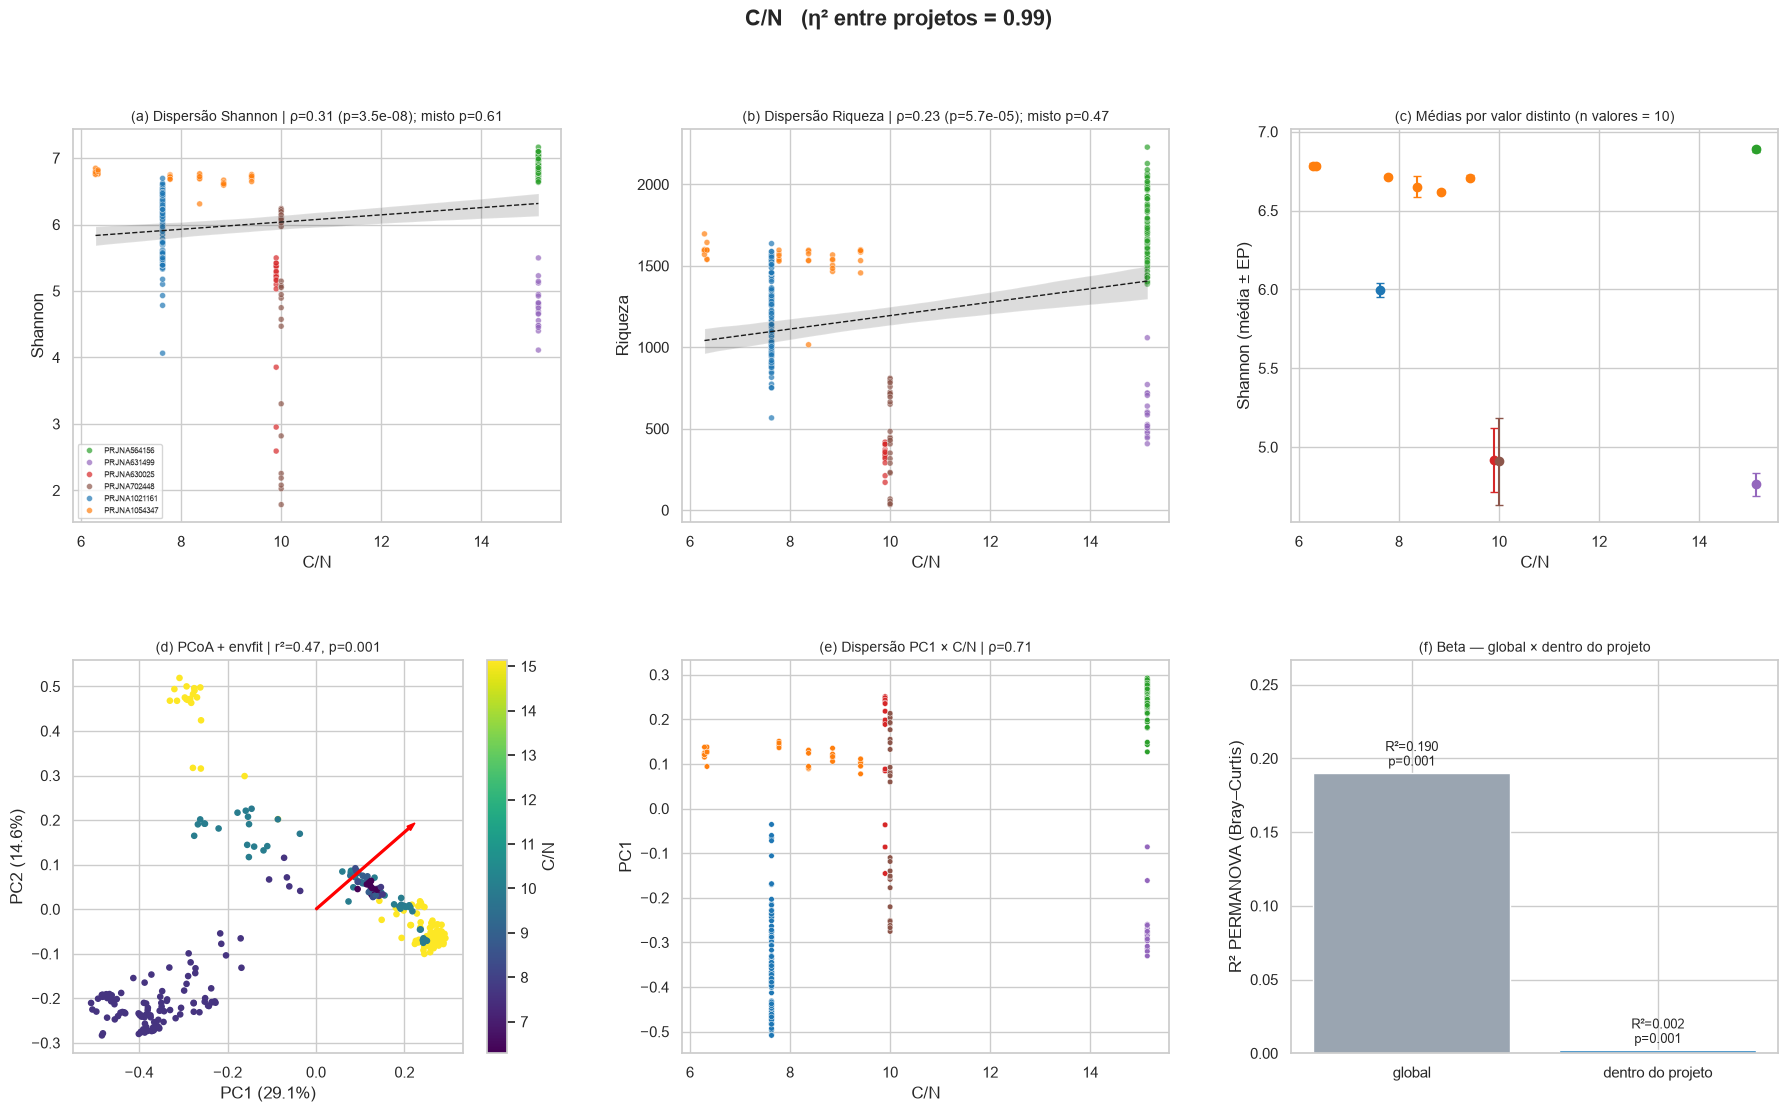


=== pH: n=459, valores distintos=17, projetos=8


,Riqueza_rho,Riqueza_spearman_p,Riqueza_misto_coef,Riqueza_misto_p,Shannon_rho,Shannon_spearman_p,Shannon_misto_coef,Shannon_misto_p,FaithPD_rho,FaithPD_spearman_p,FaithPD_misto_coef,FaithPD_misto_p,R2_global,p_global,R2_dentro_projeto,p_dentro_projeto,envfit_r2,envfit_p
pH,-0.22596,0.000001,0.122739,0.202783,-0.19372,0.000029,1.062117,5.770301e-16,-0.060529,0.195516,0.395271,0.000132,0.116554,0.001,0.02423,0.001,0.300493,0.001


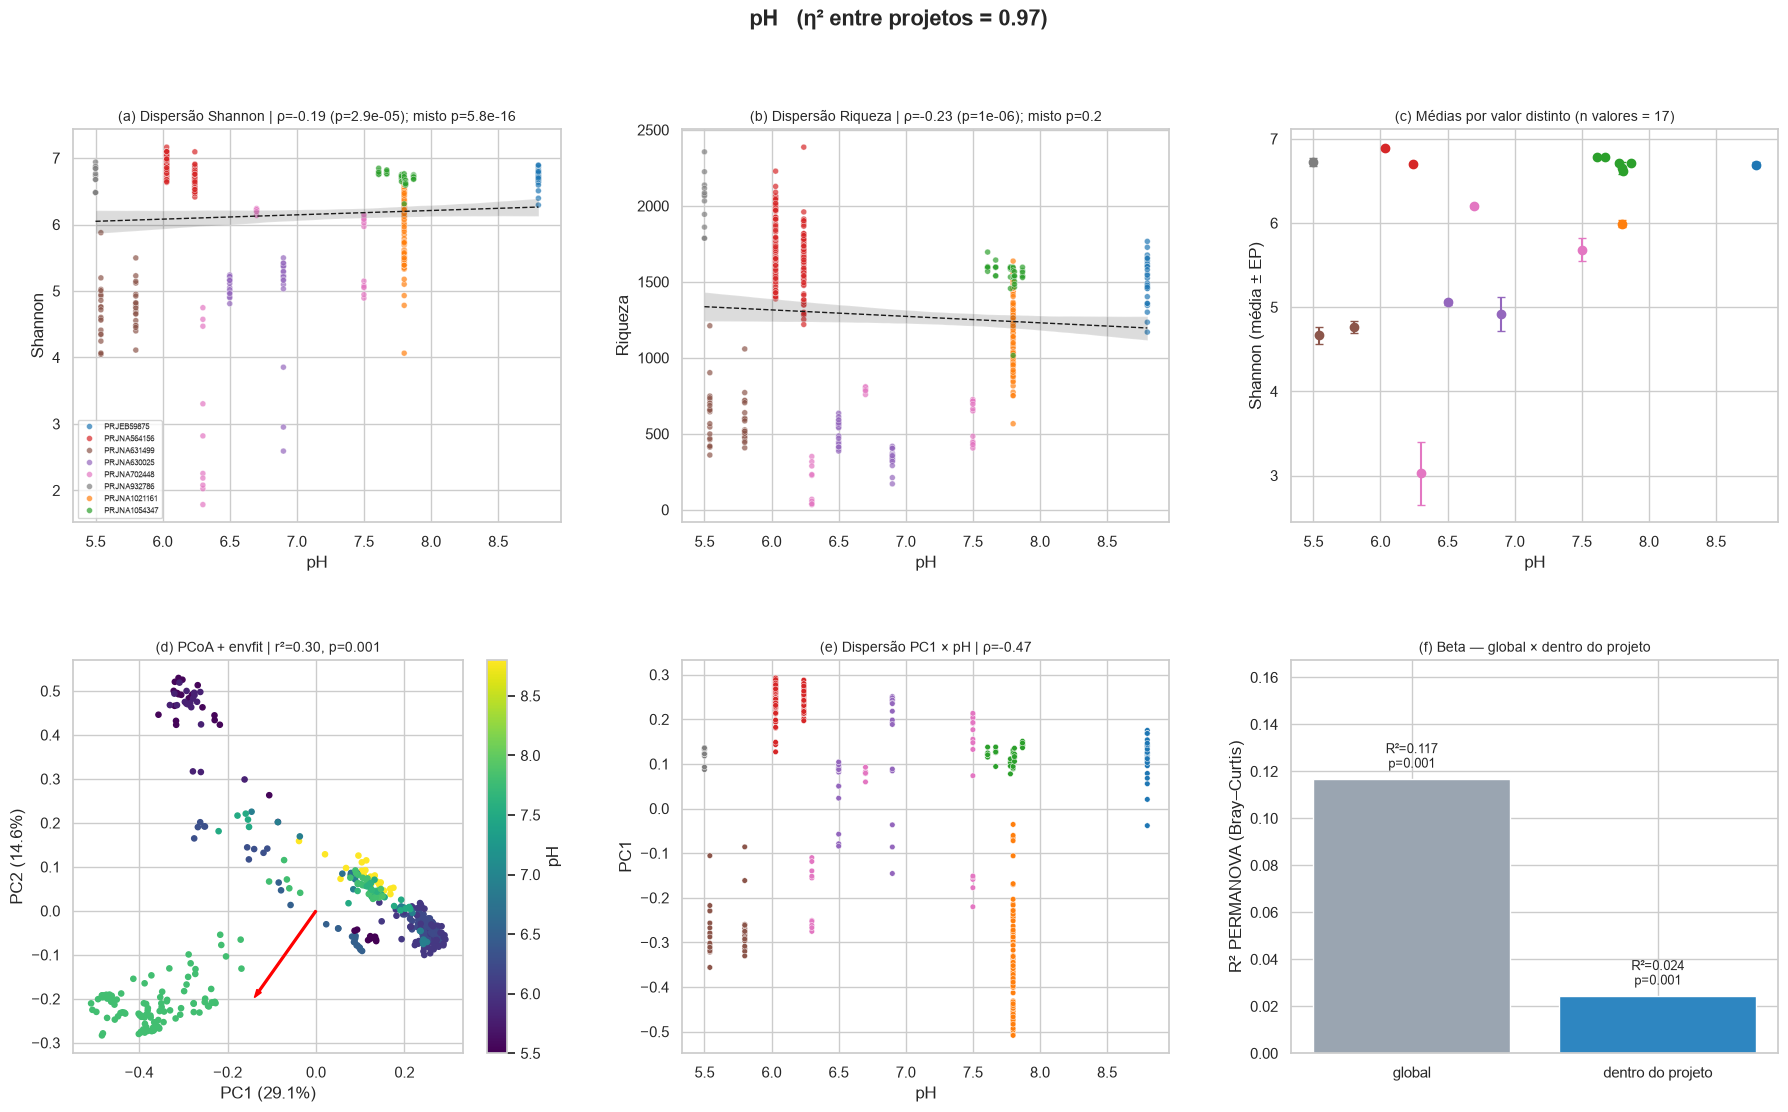


=== DOC(mg/kg): n=140, valores distintos=7, projetos=3


,Riqueza_rho,Riqueza_spearman_p,Riqueza_misto_coef,Riqueza_misto_p,Shannon_rho,Shannon_spearman_p,Shannon_misto_coef,Shannon_misto_p,FaithPD_rho,FaithPD_spearman_p,FaithPD_misto_coef,FaithPD_misto_p,R2_global,p_global,R2_dentro_projeto,p_dentro_projeto,envfit_r2,envfit_p
DOC(mg/kg),0.18261,0.030812,-0.350989,0.520589,0.300723,0.000306,-0.328654,0.487765,0.335648,0.00005,-0.44045,0.399084,0.289109,0.001,0.003062,0.001,0.090708,0.001


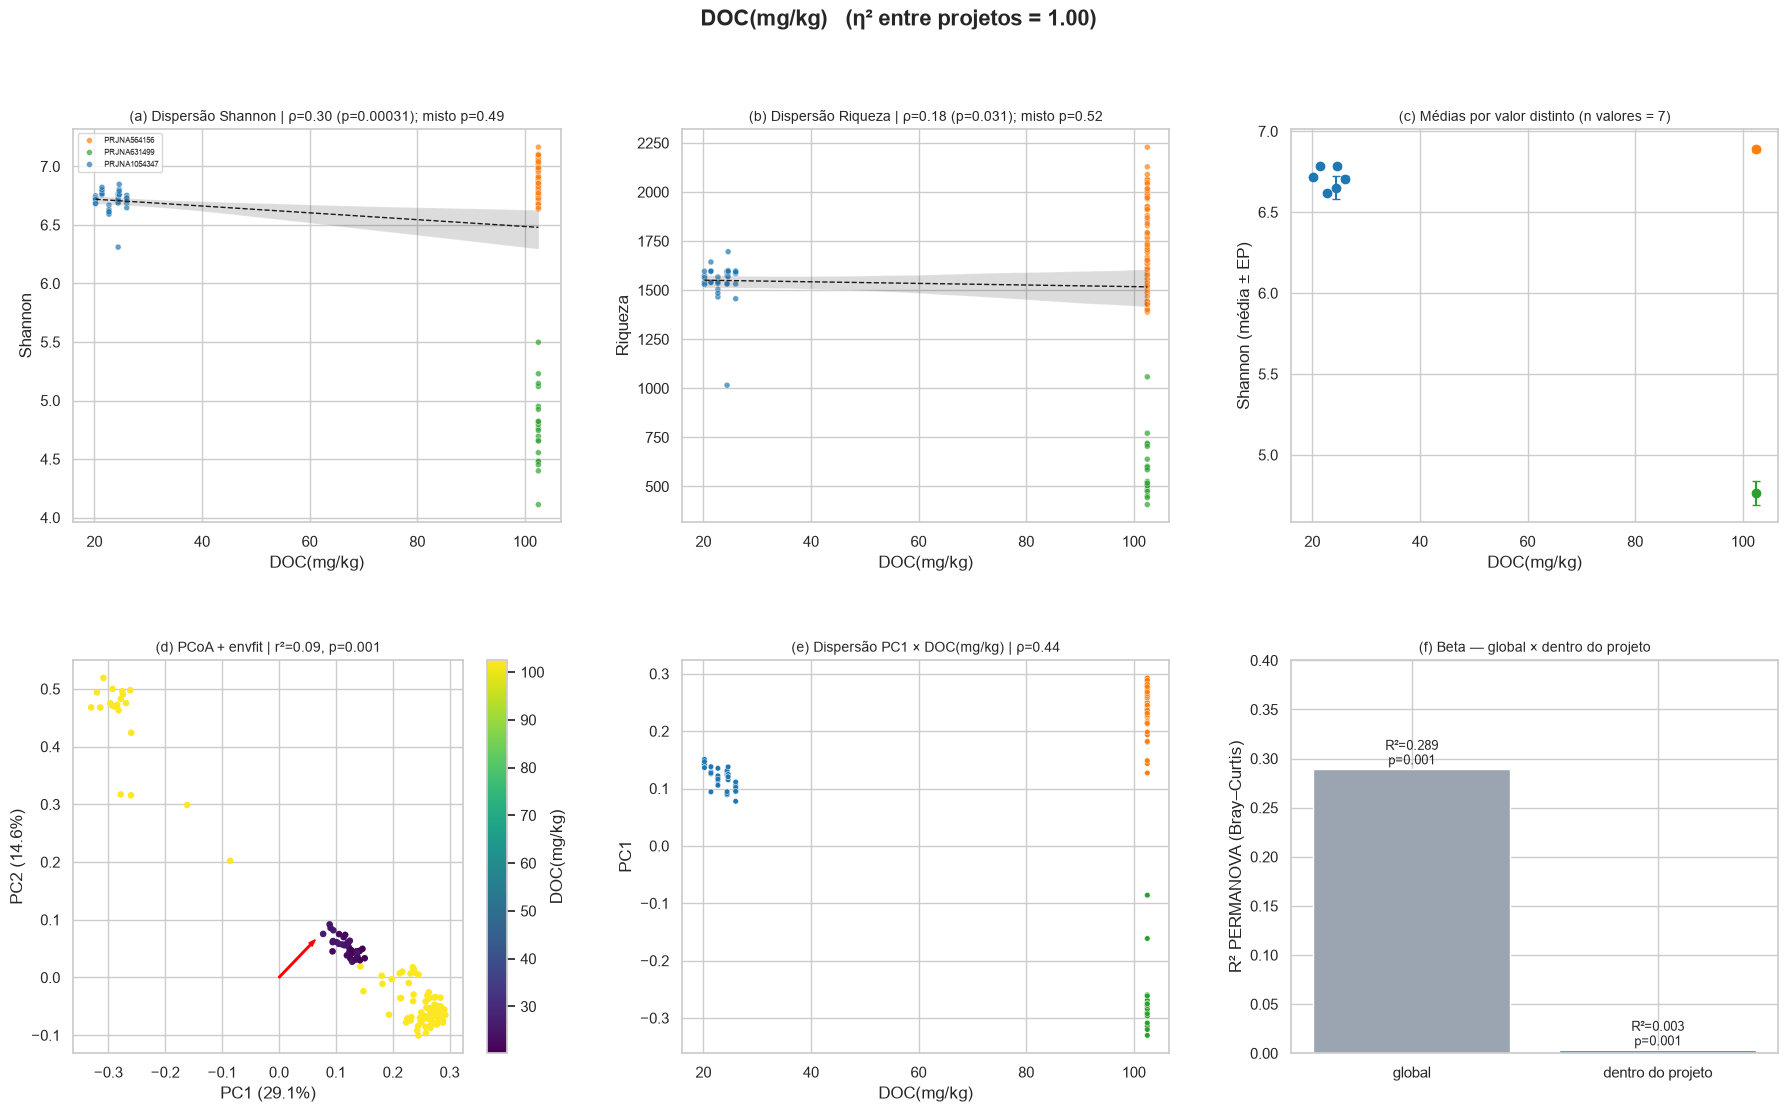


=== NH4(mg/kg): n=164, valores distintos=12, projetos=4


,Riqueza_rho,Riqueza_spearman_p,Riqueza_misto_coef,Riqueza_misto_p,Shannon_rho,Shannon_spearman_p,Shannon_misto_coef,Shannon_misto_p,FaithPD_rho,FaithPD_spearman_p,FaithPD_misto_coef,FaithPD_misto_p,R2_global,p_global,R2_dentro_projeto,p_dentro_projeto,envfit_r2,envfit_p
NH4(mg/kg),0.413356,3.774739e-08,0.038357,0.320829,0.440458,3.590892e-09,0.026337,0.50368,0.372354,9.121543e-07,0.018102,0.602073,0.098153,0.001,0.0028,0.001,0.20974,0.001


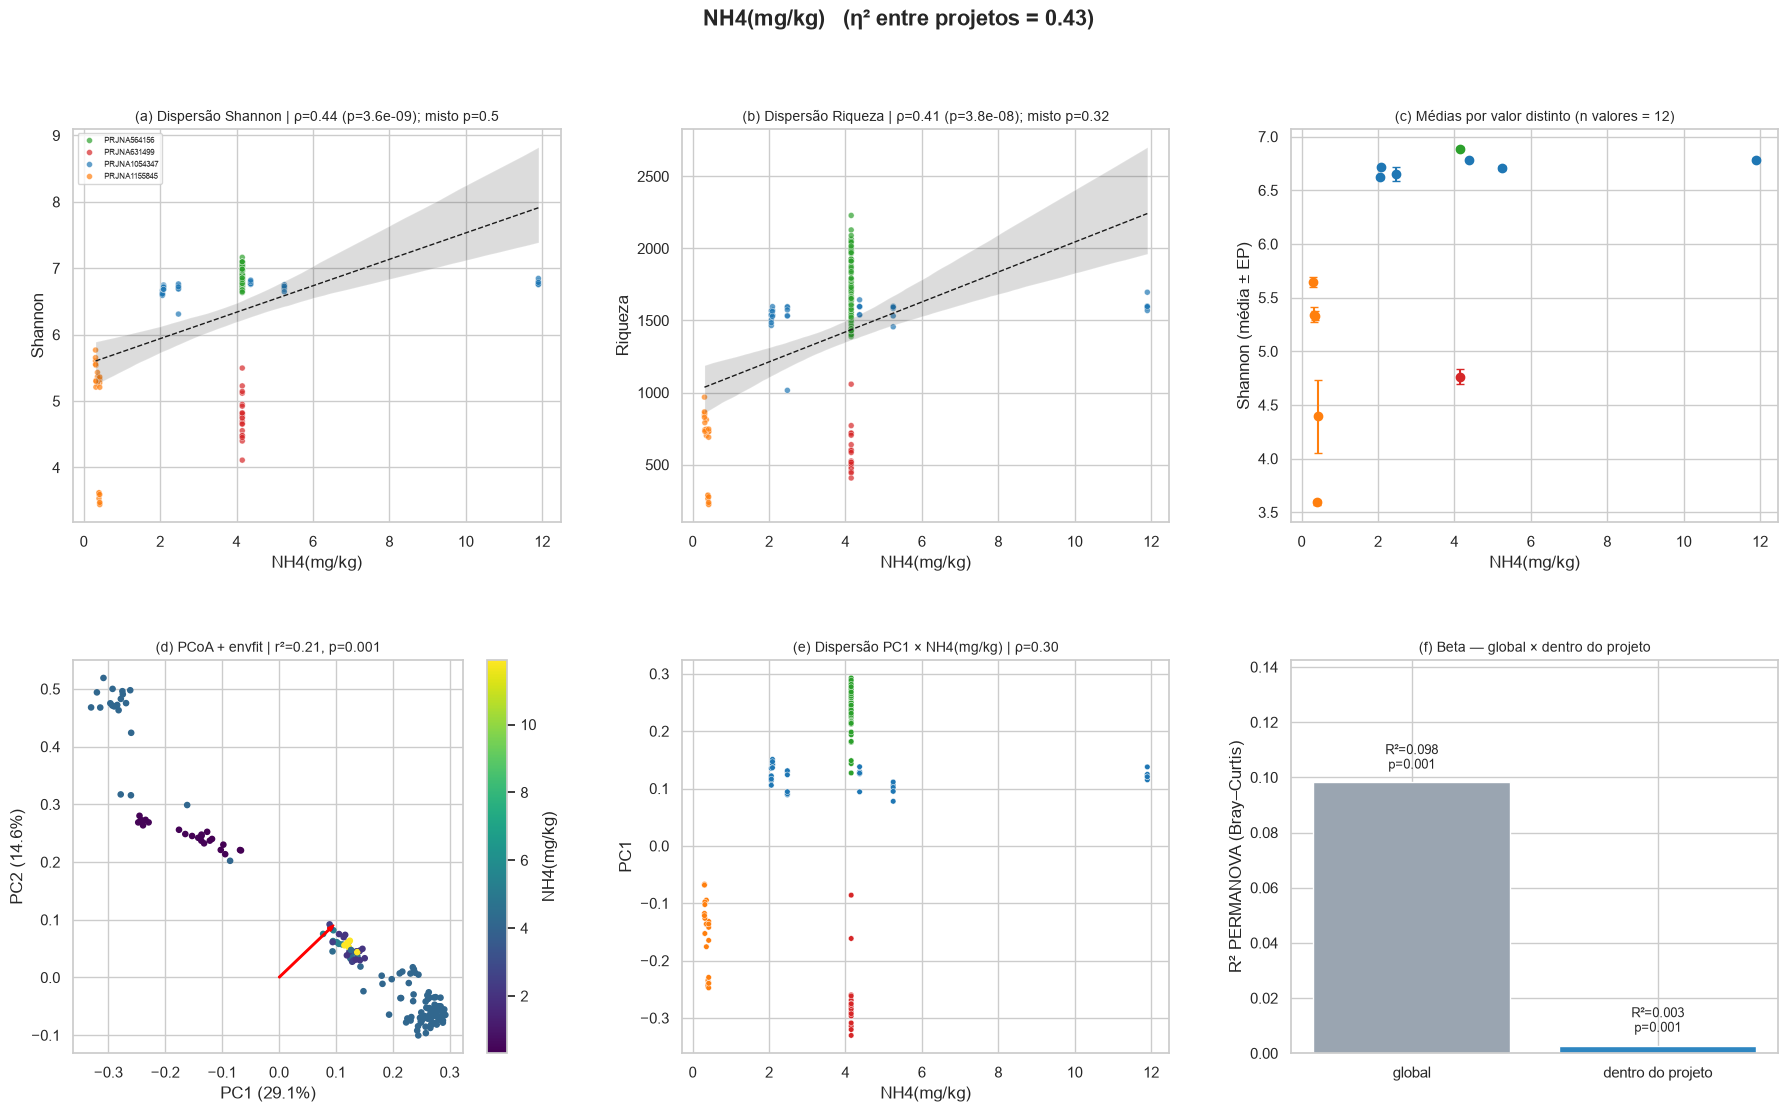


=== NO3(mg/kg): n=164, valores distintos=12, projetos=4


,Riqueza_rho,Riqueza_spearman_p,Riqueza_misto_coef,Riqueza_misto_p,Shannon_rho,Shannon_spearman_p,Shannon_misto_coef,Shannon_misto_p,FaithPD_rho,FaithPD_spearman_p,FaithPD_misto_coef,FaithPD_misto_p,R2_global,p_global,R2_dentro_projeto,p_dentro_projeto,envfit_r2,envfit_p
NO3(mg/kg),0.415525,3.150553e-08,0.041453,0.205285,0.496556,1.359445e-11,0.040091,0.229143,0.42458,1.461022e-08,0.029264,0.319681,0.040849,0.001,0.004597,0.001,0.011208,0.43


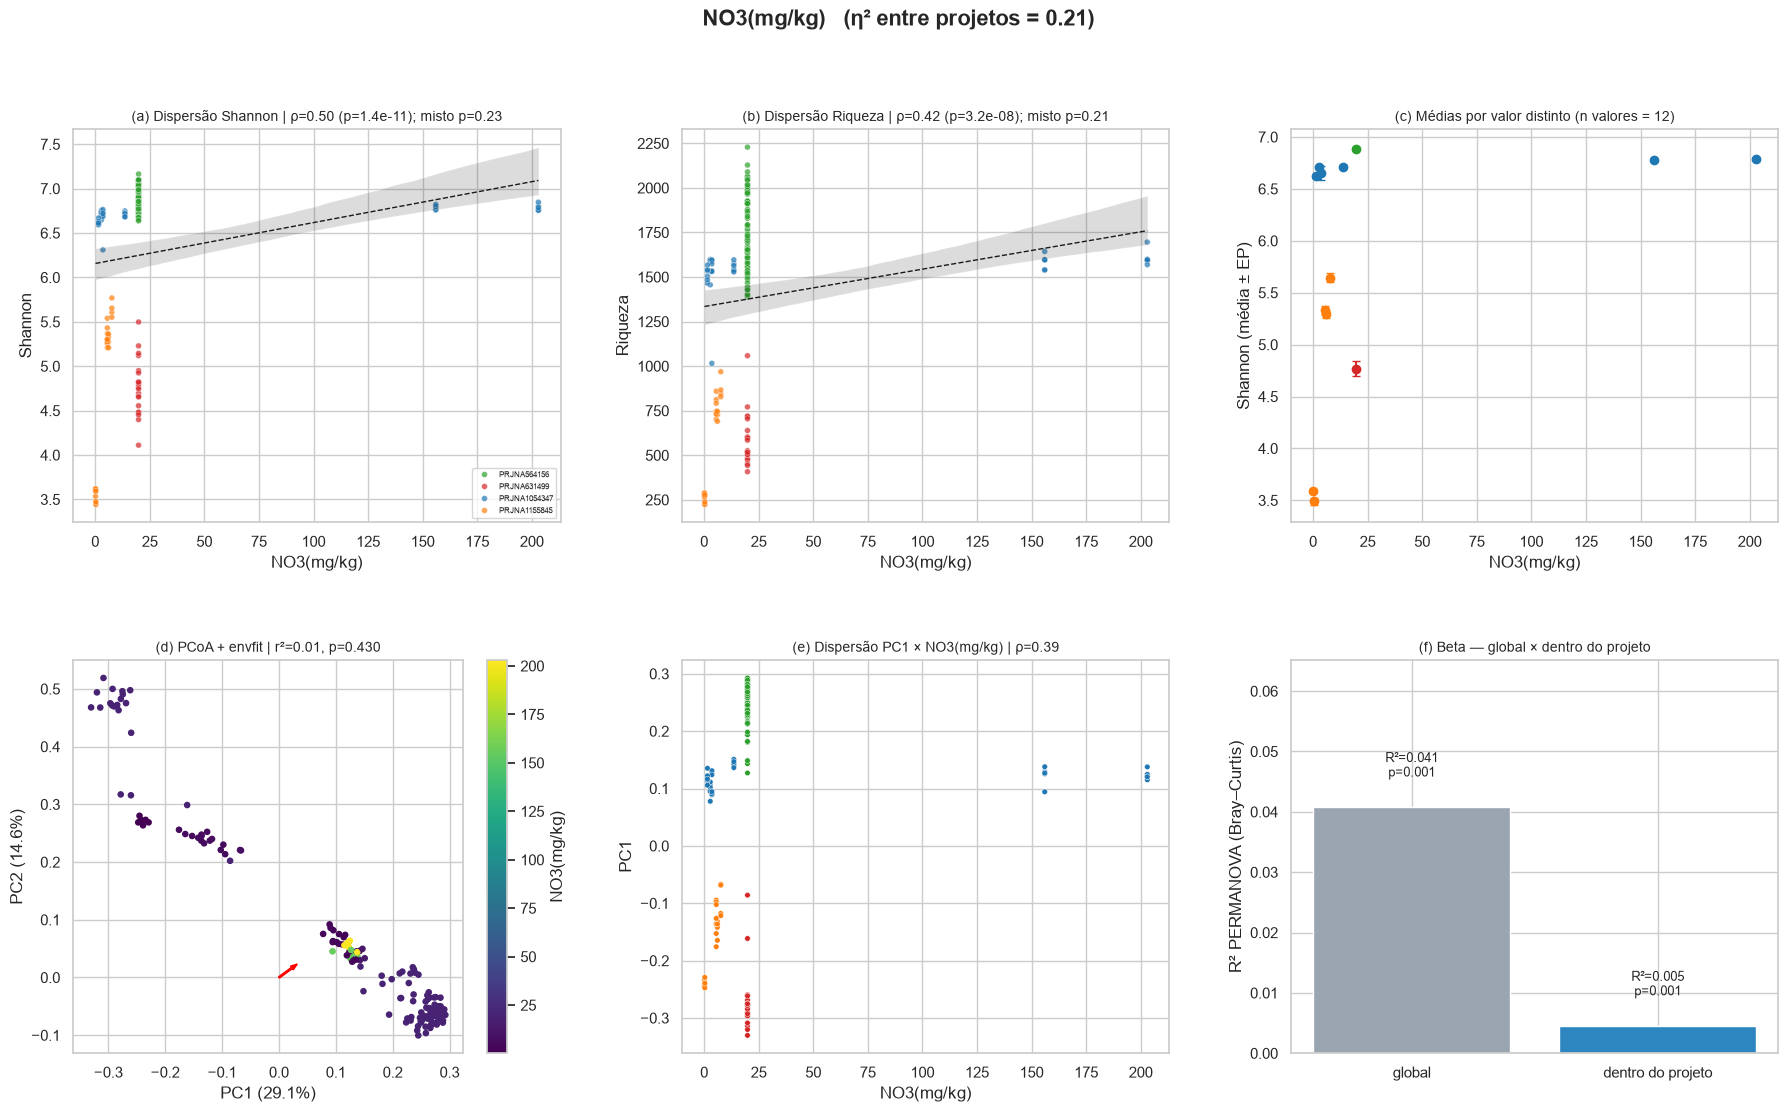


=== AP(mg/kg): n=275, valores distintos=14, projetos=5


,Riqueza_rho,Riqueza_spearman_p,Riqueza_misto_coef,Riqueza_misto_p,Shannon_rho,Shannon_spearman_p,Shannon_misto_coef,Shannon_misto_p,FaithPD_rho,FaithPD_spearman_p,FaithPD_misto_coef,FaithPD_misto_p,R2_global,p_global,R2_dentro_projeto,p_dentro_projeto,envfit_r2,envfit_p
AP(mg/kg),0.465477,3.416738e-16,0.174893,0.045394,0.508108,1.859050e-19,0.33399,0.000183,0.130932,0.029952,0.215953,0.021798,0.120035,0.001,0.004329,0.007,0.158486,0.001


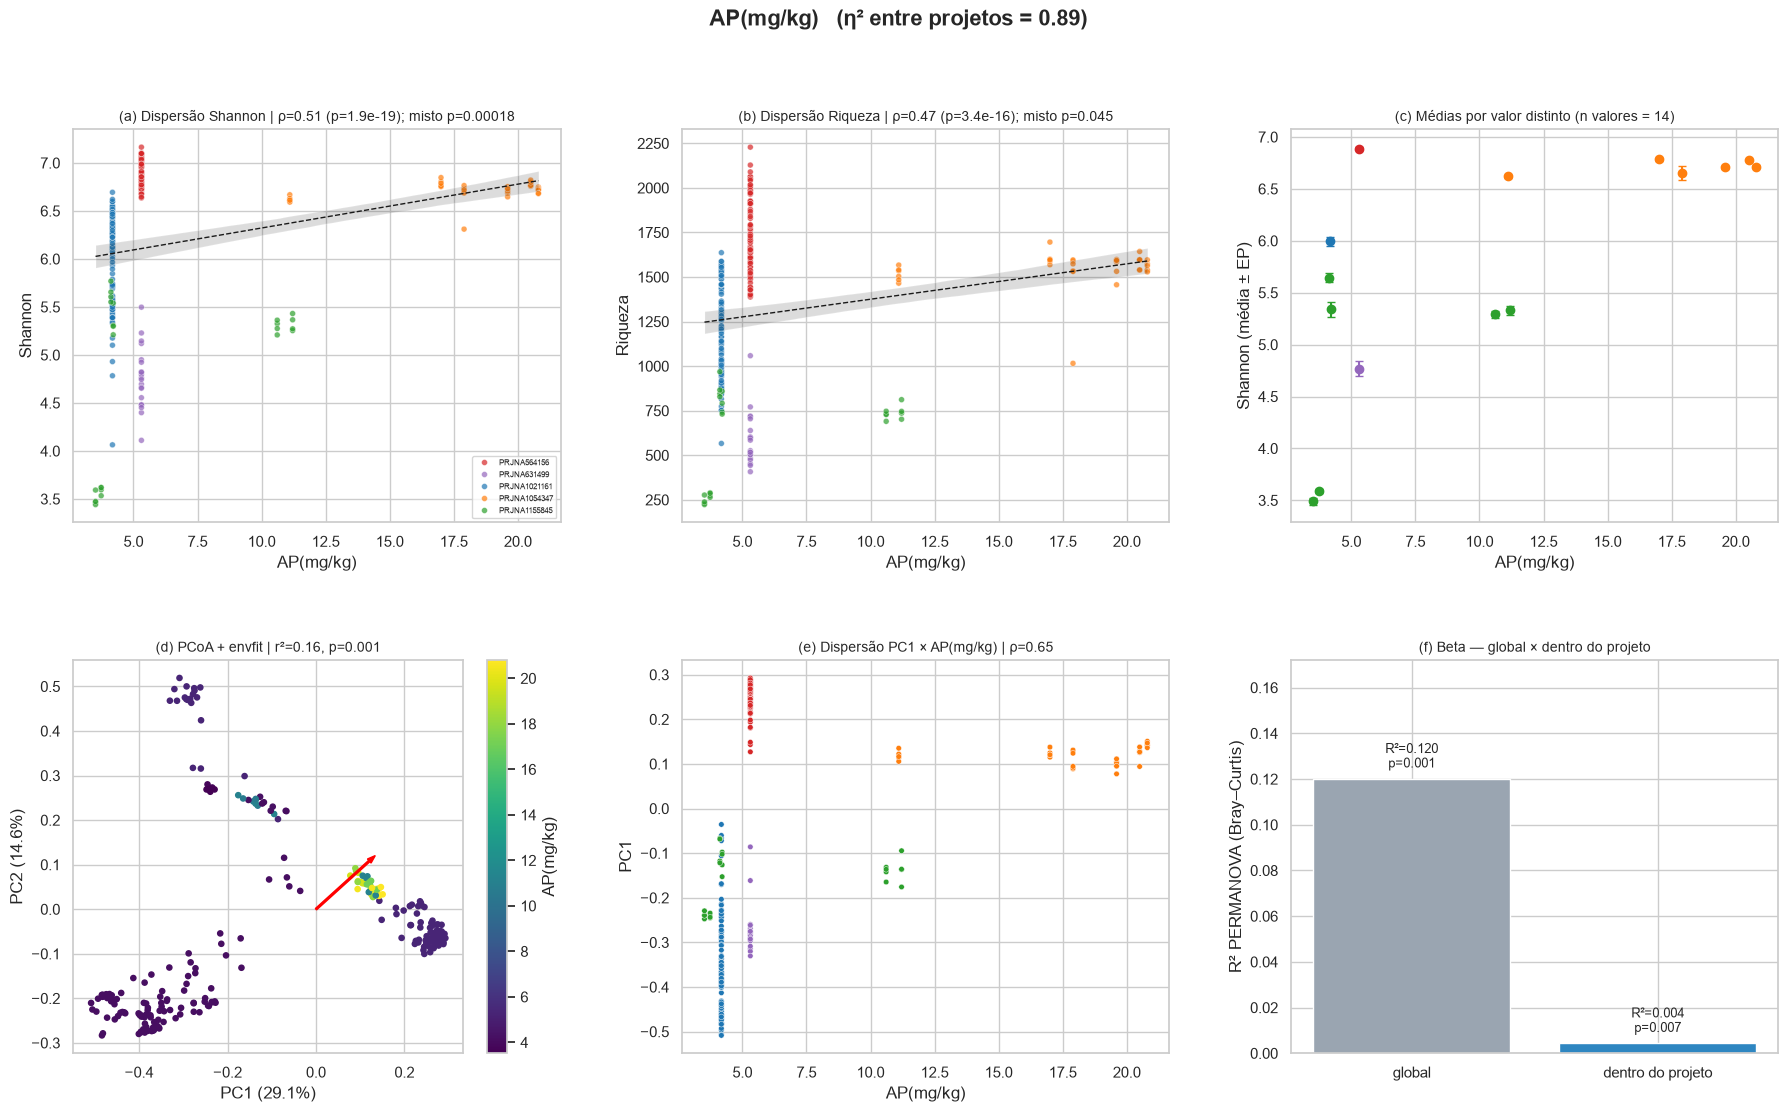


=== AK(mg/kg): n=251, valores distintos=7, projetos=4


,Riqueza_rho,Riqueza_spearman_p,Riqueza_misto_coef,Riqueza_misto_p,Shannon_rho,Shannon_spearman_p,Shannon_misto_coef,Shannon_misto_p,FaithPD_rho,FaithPD_spearman_p,FaithPD_misto_coef,FaithPD_misto_p,R2_global,p_global,R2_dentro_projeto,p_dentro_projeto,envfit_r2,envfit_p
AK(mg/kg),-0.245865,0.000083,0.114855,0.471016,-0.310344,5.257992e-07,0.092839,0.535589,-0.208394,0.000895,0.09068,0.607409,0.104957,0.001,0.001448,0.001,0.011446,0.259


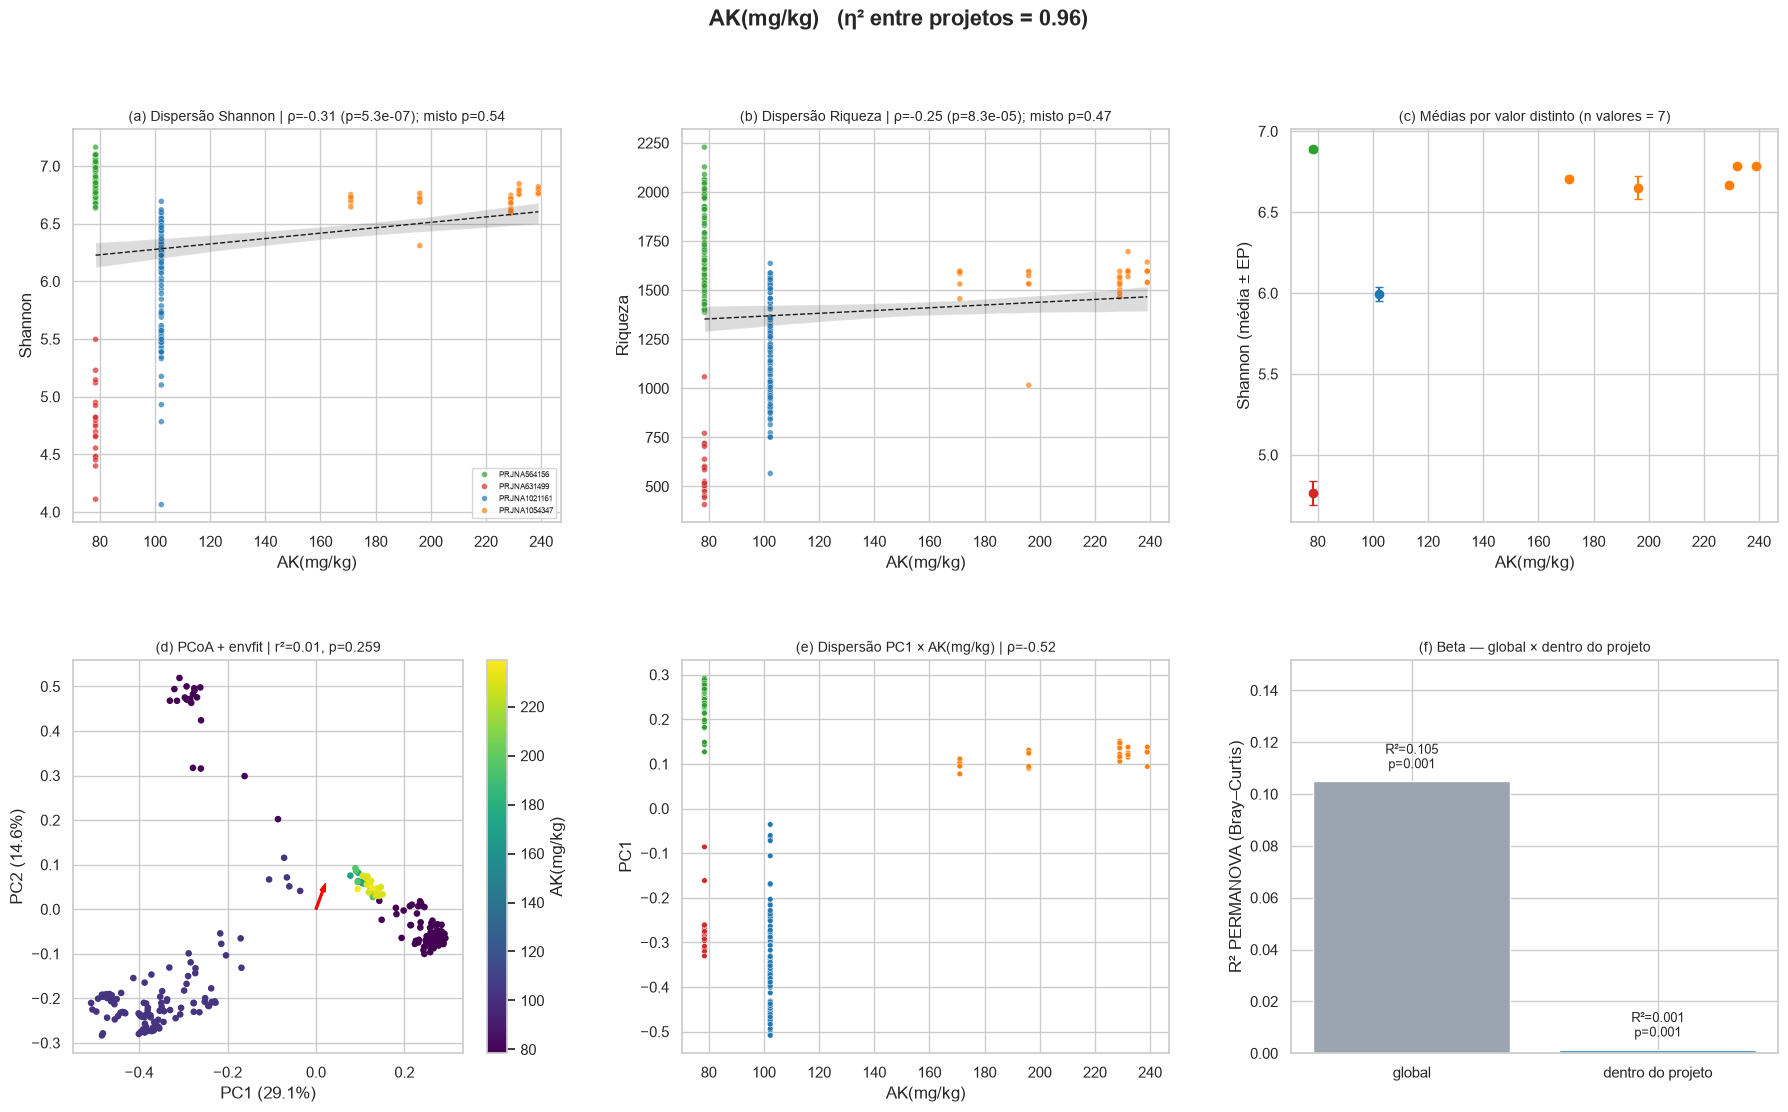

In [15]:
for i, v in enumerate(NUM, start=1):
    d = A[(A.CONJUNTO == 'solo') & A[v].notna()]
    if d[v].nunique() < 3:
        print(f'{v}: só {d[v].nunique()} valores distintos — pulado'); continue
    res = {**alfa_numerica(d, v), **beta(d, v, list(d.index))}
    r2, p, dirv = envfit(PCs, d, v); res.update(envfit_r2=r2, envfit_p=p, envfit_dir=dirv)
    RES[v] = res
    print(f"\n=== {v}: n={len(d)}, valores distintos={d[v].nunique()}, projetos={d.BIOPROJECT.nunique()}")
    display(pd.Series({k: x for k, x in res.items() if k != 'envfit_dir'}).to_frame(v).T)
    fig_numerica(v, d, PCs, VEs, res, f'{10 + i:02d}_num_' + re.sub(r'\W+', '_', v).strip('_').lower())

## 7. Validação por aprendizado de máquina (Random Forest)

Se uma variável realmente molda a comunidade, deve ser possível **prevê-la a partir dos gêneros**, inclusive em um **projeto que o
modelo nunca viu**. Comparamos duas validações cruzadas:
* **Misturando projetos (5 folds estratificados):** mede o sinal total (inclui diferença entre estudos).
* **Projeto novo (GroupKFold por BioProject):** o teste é sempre um estudo que não estava no treino → mede se o padrão **generaliza**.
Métrica: acurácia balanceada (acaso = 1 / nº de classes).

,n,classes,acaso,acc_bal_misturando_projetos,acc_bal_projeto_novo
alvo,,,,,
SOIL_FRACTION,483,3,0.333,0.950,0.485
BIODEGRADABLE,483,3,0.333,0.610,0.383
PLASTICO,483,2,0.500,0.628,0.614


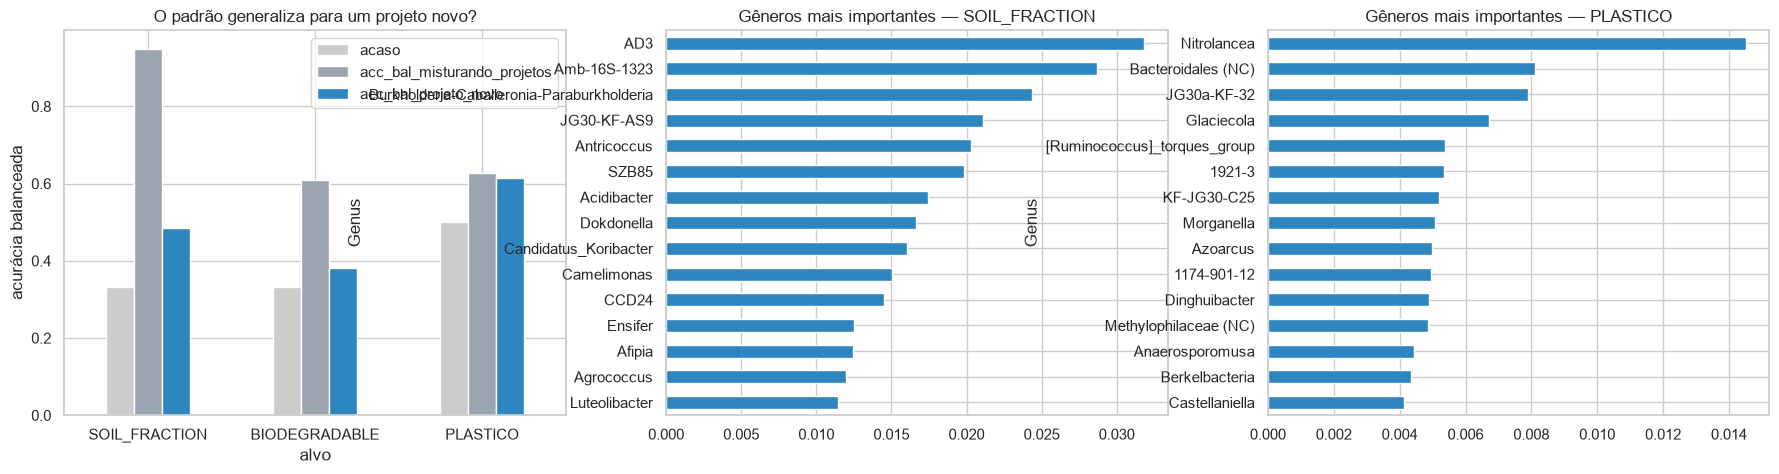

In [16]:
from sklearn.ensemble import RandomForestClassifier
from sklearn.model_selection import StratifiedKFold, GroupKFold, cross_val_predict
from sklearn.metrics import balanced_accuracy_score

G = clr(gen.loc[(gen > 0).mean(1) >= .10] * DEPTH).T            # amostras × gêneros (CLR)
meta['PLASTICO'] = np.where(meta.POLYMER_TYPE.isin(['Controle (NONE)', 'NA (papel)']), 'sem plástico', 'plástico')
alvos = {'SOIL_FRACTION': ['Bulk', 'Plastisphere', 'Rhizosphere'],
         'BIODEGRADABLE': ['Biodegradable', 'Non_biodegradable', 'NA (sem plástico)'],
         'PLASTICO': None}
rows, imp = [], {}
for alvo, classes in alvos.items():
    d = meta[meta.CONJUNTO == 'solo']
    if classes: d = d[d[alvo].isin(classes)]
    y = d[alvo].values; X = G.loc[d.index].values; grp = d.BIOPROJECT.values
    rf = RandomForestClassifier(n_estimators=400, class_weight='balanced', random_state=0, n_jobs=-1)
    p1 = cross_val_predict(rf, X, y, cv=StratifiedKFold(5, shuffle=True, random_state=0))
    p2 = cross_val_predict(rf, X, y, cv=GroupKFold(n_splits=min(5, len(set(grp)))), groups=grp)
    rows.append(dict(alvo=alvo, n=len(y), classes=len(set(y)), acaso=1 / len(set(y)),
                     acc_bal_misturando_projetos=balanced_accuracy_score(y, p1), acc_bal_projeto_novo=balanced_accuracy_score(y, p2)))
    imp[alvo] = pd.Series(rf.fit(X, y).feature_importances_, index=G.columns).sort_values(ascending=False).head(15)
RF = pd.DataFrame(rows).set_index('alvo'); RF.round(3).to_csv(TAB / '07_random_forest.csv'); display(RF.round(3))

fig, axes = plt.subplots(1, 3, figsize=(22, 5))
RF[['acaso', 'acc_bal_misturando_projetos', 'acc_bal_projeto_novo']].plot.bar(ax=axes[0], color=['#cccccc', '#9aa5b1', '#2e86c1'])
axes[0].set_ylabel('acurácia balanceada'); axes[0].set_title('O padrão generaliza para um projeto novo?'); axes[0].tick_params(axis='x', rotation=0)
for ax, alvo in zip(axes[1:], ['SOIL_FRACTION', 'PLASTICO']):
    imp[alvo].iloc[::-1].plot.barh(ax=ax, color='#2e86c1'); ax.set_title(f'Gêneros mais importantes — {alvo}')
savefig('07_random_forest')

## 8. Síntese — padrões e validação

In [17]:
linhas = []
for v, r in RES.items():
    linhas.append(dict(variavel=v, tipo='categórica' if v in CAT else 'numérica',
                       confusao_projeto=CONF.at[v, 'associacao_com_projeto'], diagnostico=CONF.at[v, 'diagnostico'],
                       Shannon_misto_p=r.get('Shannon_misto_p'), Riqueza_misto_p=r.get('Riqueza_misto_p'),
                       R2_global=r['R2_global'], p_global=r['p_global'], R2_dentro_projeto=r['R2_dentro_projeto'], p_dentro_projeto=r['p_dentro_projeto'],
                       PERMDISP_p=r.get('PERMDISP_p'), envfit_r2=r.get('envfit_r2')))
S = pd.DataFrame(linhas).set_index('variavel')
S['projetos_com_variacao'] = CONF.loc[S.index, 'projetos_com_variacao']
def veredito(r):
    if pd.isna(r.R2_dentro_projeto): return 'não testável dentro do projeto (= diferença entre estudos)'
    if r.p_dentro_projeto >= .05: return 'sem efeito quando o projeto é controlado'
    if r.tipo == 'numérica' and r.name != 'DENSITY_(g/cm³)':
        return (f'varia dentro de {int(r.projetos_com_variacao)} projeto(s), mas como média por sítio ou tratamento '
                '(não medida por amostra) → confundida com sítio/tratamento')
    if r.name == 'DENSITY_(g/cm³)':
        return 'efeito pequeno; densidade é propriedade do polímero (equivale a POLYMER_TYPE)'
    if r.R2_dentro_projeto >= .01: return 'efeito validado dentro do projeto'
    return 'efeito pequeno, mas consistente'
S['veredito'] = S.apply(veredito, axis=1)
S.round(4).to_csv(TAB / '08_sintese.csv'); S.round(3)

,tipo,confusao_projeto,diagnostico,Shannon_misto_p,Riqueza_misto_p,R2_global,p_global,R2_dentro_projeto,p_dentro_projeto,PERMDISP_p,envfit_r2,projetos_com_variacao,veredito
variavel,,,,,,,,,,,,,
SOIL_FRACTION,categórica,0.737,fortemente confundida,0.000,0.000,0.251,0.001,0.084,0.001,0.0,NaN,5,efeito validado dentro do projeto
POLYMER_TYPE,categórica,0.606,fortemente confundida,0.000,0.000,0.271,0.001,0.034,0.001,0.0,NaN,9,efeito validado dentro do projeto
BIODEGRADABLE,categórica,0.386,separável,0.000,0.020,0.054,0.001,0.005,0.001,0.0,NaN,9,"efeito pequeno, mas consistente"
POLYMER_SIZE,categórica,0.805,fortemente confundida,0.000,0.000,0.384,0.001,0.027,0.001,0.0,NaN,8,efeito validado dentro do projeto
DENSITY_(g/cm³),numérica,0.281,separável,0.224,0.410,0.039,0.001,0.002,0.009,NaN,0.166,8,efeito pequeno; densidade é propriedade do pol...
SOC(g/kg),numérica,0.791,fortemente confundida,0.073,0.001,0.142,0.001,0.025,0.001,NaN,0.432,3,"varia dentro de 3 projeto(s), mas como média p..."
TN(g/kg),numérica,0.578,separável,0.000,0.000,0.073,0.001,0.025,0.001,NaN,0.194,3,"varia dentro de 3 projeto(s), mas como média p..."
C/N,numérica,0.985,quase totalmente confundida,0.607,0.474,0.190,0.001,0.002,0.001,NaN,0.465,1,"varia dentro de 1 projeto(s), mas como média p..."
pH,numérica,0.966,quase totalmente confundida,0.000,0.203,0.117,0.001,0.024,0.001,NaN,0.300,5,"varia dentro de 5 projeto(s), mas como média p..."


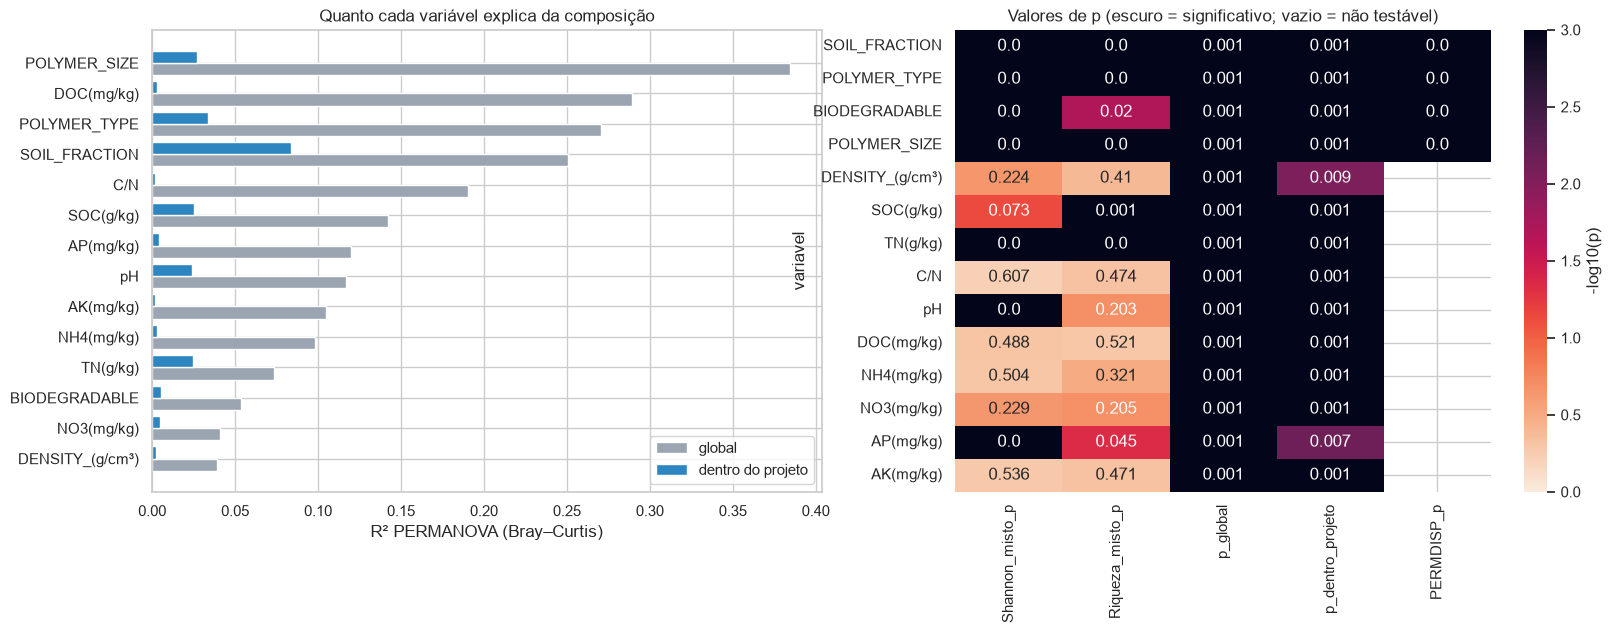

In [18]:
fig, axes = plt.subplots(1, 2, figsize=(19, 6))
s = S.sort_values('R2_global'); y = np.arange(len(s))
axes[0].barh(y - .2, s.R2_global, .4, label='global', color='#9aa5b1')
axes[0].barh(y + .2, s.R2_dentro_projeto.fillna(0), .4, label='dentro do projeto', color='#2e86c1')
axes[0].set_yticks(y, s.index); axes[0].set_xlabel('R² PERMANOVA (Bray–Curtis)'); axes[0].legend(); axes[0].set_title('Quanto cada variável explica da composição')
cols = ['Shannon_misto_p', 'Riqueza_misto_p', 'p_global', 'p_dentro_projeto', 'PERMDISP_p']
Pv = S[cols].astype(float)
sns.heatmap(-np.log10(Pv), annot=Pv.round(3), fmt='', cmap='rocket_r', vmin=0, vmax=3, ax=axes[1], cbar_kws={'label': '-log10(p)'})
axes[1].set_title('Valores de p (escuro = significativo; vazio = não testável)')
savefig('08_sintese')